# Spotify Genre Classification

### About the Dataset

This dataset is from Kaggle and contains Spotify tracks from a wide range of genres. 
The Kaggle page says 125 genres, but the file itself contains 114 genres with 1,000 tracks each, 
which gives 114,000 tracks in total. Each track has a set of audio features that describe 
how the song sounds, like how danceable, energetic or loud it is.

The data is in CSV format, which is tabular and quick to load with pandas.

Link: https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset

Credit goes to Maharshi Pandya.
### Goal

The goal is to predict the genre of a song based on its audio features. This is a multiclass 
classification problem, since there are more than two possible genres.

I compare two baseline models, three ensemble models and two neural networks. As an extra, I also
combine the best models in a stacking ensemble. Besides the scores, I want to understand which
features separate the genres from each other, and which mistakes the models make.

##### Understanding the Audio Features

To help understand how the models separate the genres, here is a simple explanation of what each audio feature actually measures:

* **Popularity:** A score from 0 to 100 based on how many times a song has been played recently.
* **Duration_ms:** The length of the track measured in milliseconds.
* **Explicit:** A true/false (1 or 0) value showing if the song contains lyrics that are not suitable for children.
* **Danceability:** How suitable a track is for dancing based on tempo, rhythm stability, and beat strength (from 0.0 to 1.0).
* **Energy:** A measure from 0.0 to 1.0 representing intensity and activity. High energy feels fast, loud, and noisy (like heavy metal).
* **Key:** The overall key the track is in (e.g., C, C#, D) using standard pitch notation.
* **Loudness:** The overall loudness of a track in decibels (dB), usually ranging between -60 and 0 dB.
* **Mode:** The modality of a track (Major = 1, Minor = 0), which often defines if a song sounds "happy" or "sad".
* **Speechiness:** Detects the presence of spoken words. A value close to 1.0 means it is mostly talking (like a podcast or rap), while lower values mean music.
* **Acousticness:** A score from 0.0 to 1.0 showing how likely it is that the song uses acoustic instruments (like an acoustic guitar or piano) rather than electronic ones.
* **Instrumentalness:** Predicts whether a track contains no vocals. The closer to 1.0, the more likely the song has no singing at all.
* **Liveness:** Detects the presence of an audience in the recording. Higher values mean the song was probably recorded live at a concert.
* **Valence:** A measure from 0.0 to 1.0 describing the musical positiveness. High valence sounds happy/cheerful, while low valence sounds sad/angry.
* **Tempo:** The overall speed of the track measured in Beats Per Minute (BPM).
* **Time_signature:** An estimated time signature, meaning the number of beats in each bar (for example 3 = 3/4 and 4 = 4/4).


* **Unnamed: 0:** A leftover row number from when the file was saved. Not a real feature.
* **Track_id:** Spotify's unique ID for each track.
* **Artists, Album_name, Track_name:** Who made the song, which album it's from, and its title.
* **Track_genre:** The genre of the track. **This is the label we want to predict.**

## Contents

1. **Exploratory data analysis:** the full dataset, choosing six genres, data quality, distributions,
   outliers, correlation, and how the features differ between the genres
2. **Preprocessing:** cleaning (including re-released copies of the same song), encoding,
   train/test split, and a pipeline with several processing alternatives
3. **Models:** a random-guess reference, two baselines (Decision Tree, KNN), three ensembles
   (Random Forest, Gradient Boosting, Extra Trees) and two neural networks (MLP, Keras), all tuned
   automatically with cross-validation. As an extra, a stacking ensemble that combines the best models
4. **Evaluation:** cross-validation comparison, test results, confusion matrices, ROC and
   precision-recall curves
5. **Further analysis:** how much `popularity` adds, which features matter most, which songs the
   best model gets wrong, and whether more data would help
6. **Conclusion**

# EXPLORATORY DATA ANALYSIS

In [1]:
# The Keras backend has to be chosen BEFORE keras is imported for the first time.
# I use PyTorch as the backend, since TensorFlow does not support my Python version (3.14) yet.
import os
os.environ["KERAS_BACKEND"] = "torch"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

# Preprocessing
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (LabelEncoder, MinMaxScaler, OneHotEncoder,
                                   PowerTransformer, StandardScaler, label_binarize)

# Tuning and validation
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_score, learning_curve)

# Models
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

# Evaluation
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.inspection import permutation_importance

# Neural network with Keras
import keras
import scikeras
from scikeras.wrappers import KerasClassifier

# One random_state for the whole notebook, so every run gives the same split and results
random_state = 42
keras.utils.set_random_seed(random_state)

In [2]:
df = pd.read_csv("../dataset/spotify.csv")

In [3]:
df.head(10) # checking the data and their rows

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
5,5,01MVOl9KtVTNfFiBU9I7dc,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,214240,False,0.688,0.4810,...,-8.807,1,0.1050,0.2890,0.000000,0.1890,0.6660,98.017,4,acoustic
6,6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,229400,False,0.407,0.1470,...,-8.822,1,0.0355,0.8570,0.000003,0.0913,0.0765,141.284,3,acoustic
7,7,1EzrEOXmMH3G43AXT1y7pA,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,242946,False,0.703,0.4440,...,-9.331,1,0.0417,0.5590,0.000000,0.0973,0.7120,150.960,4,acoustic
8,8,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.4140,...,-8.700,1,0.0369,0.2940,0.000000,0.1510,0.6690,130.088,4,acoustic
9,9,7k9GuJYLp2AzqokyEdwEw2,Ross Copperman,Hunger,Hunger,56,205594,False,0.442,0.6320,...,-6.770,1,0.0295,0.4260,0.004190,0.0735,0.1960,78.899,4,acoustic


In [4]:
df.shape # Tells us the amount of instances and features in the dataset 

(114000, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

### Interpretation

The dataset contains 114,000 rows and 21 columns. Most columns have complete data, but `artists`, 
`album_name` and `track_name` each have one missing value.

There are 1 bool, 9 float, 6 integer and 5 text columns. Some integer columns are really 
categories: `key`, `mode` and `time_signature`. A higher number there does not mean "more", 
so they need to be handled as categories later.

#### Missing values

`info()` showed that `artists`, `album_name` and `track_name` each have one missing value. 
Here I check exactly where they are, and whether it is the same row.

In [6]:
df.isnull().sum() # checking for null values in the dataset

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [7]:
df[df['artists'].isnull()]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


#### Interpretation

`artists`, `album_name` and `track_name` are all missing in the same row. This row also has 
`duration_ms = 0`, which is not possible for a real song, so it looks like a broken entry.

Since it is only 1 row out of 114,000, removing it will not affect the analysis. 
I will drop it in preprocessing.

#### Duplicates

Here I check if the dataset counts some songs more than once. Copies can make the model 
see the same song in both training and test data, which gives results that look better 
than they really are.

In [8]:
# Check for exact duplicate rows
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


In [9]:
# Check duplicates without the index column
duplicates = df.drop(columns='Unnamed: 0').duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 450


In [10]:
# Comparing the number of rows with the number of unique songs.
# The same track_id means the same song.
print(f"Total rows: {len(df)}")
print(f"Unique songs: {df['track_id'].nunique()}")
print(f"Repeated songs: {df['track_id'].duplicated().sum()}")

Total rows: 114000
Unique songs: 89741
Repeated songs: 24259


Unique songs (89,741): every different song, counted once.

Repeated songs (24,259): every extra time a song shows up after its first appearance

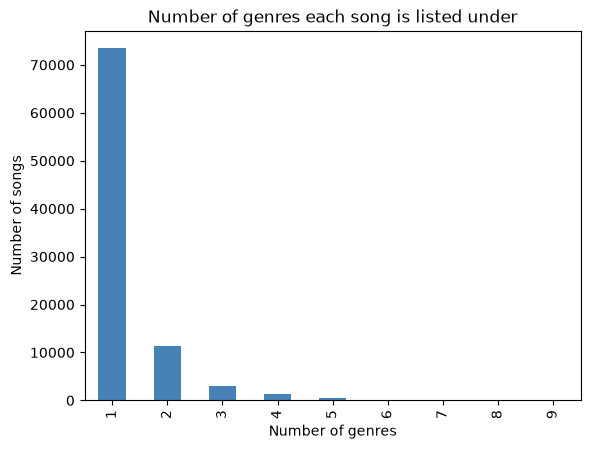

In [11]:
# How many different genres is each song listed under?
genres_per_song = df.groupby('track_id')['track_genre'].nunique()

genres_per_song.value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Number of genres each song is listed under')
plt.xlabel('Number of genres')
plt.ylabel('Number of songs')
plt.show()

In [12]:
print(genres_per_song.value_counts().sort_index())

track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64


In [13]:
# Check if repeated songs have the same audio values
audio = ['danceability', 'energy', 'tempo', 'loudness', 'valence']
print(f"Repeats with the same audio values: {df.duplicated(subset=['track_id'] + audio).sum()}")

Repeats with the same audio values: 24259


#### Interpretation

At first it looked like there were no duplicates, but that was because `Unnamed: 0` gives every 
row its own number. Without it, there are 450 rows that are exact copies.

There are also fewer unique songs than rows, so many songs appear more than once. The plot shows 
that most songs belong to one genre, but a lot of songs are listed under two or more. When a song 
appears again, its audio values are exactly the same. Only the genre is different.

This is a problem for two reasons. The model sees the same song with different answers, so it 
can't learn what separates those genres. And copies of the same song could end up in both the 
training and test data, which would make the results look better than they really are.

I will handle this in preprocessing.

### Summary statistics

Here I look at the basic numbers for each numeric column: the average, the smallest and largest 
value, and how spread out the values are. The goal is to spot values that look wrong or unrealistic.

In [14]:
# Summary statistics for all numeric columns.
# .T flips the table so each column becomes a row, which is easier to read.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.500000,32909.109681,0.000,28499.75000,56999.500000,85499.2500,113999.000
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996


count: how many values

mean: the average

std: how spread out the values are

min / max: the smallest and largest value

25%, 50%, 75%: a quarter of the songs are below the 25% value, half are below 50% (the median), and so on

In [15]:
# Count values that are not possible, or unusual, for a real song
print(f"Songs with tempo 0: {(df['tempo'] == 0).sum()}")
print(f"Songs with time_signature 0: {(df['time_signature'] == 0).sum()}")
print(f"Songs with duration 0: {(df['duration_ms'] == 0).sum()}")
print(f"Songs louder than 0 dB: {(df['loudness'] > 0).sum()}")

Songs with tempo 0: 157
Songs with time_signature 0: 163
Songs with duration 0: 1
Songs louder than 0 dB: 90


### Interpretation

Most values look realistic, but some are not possible for a real song:

- 157 songs have a tempo of 0 and 163 songs have a time signature of 0. A song without a beat 
  can't be measured, so these zeros most likely mean "missing" rather than a real value.
- 1 song has a duration of 0. This is the broken row from the missing values step.

Some values are unusual, but possible:

- The longest song in the full dataset is about 87 minutes. This could be a long classical or ambient track.
- 90 songs are louder than 0 dB, which is above the normal range. This can happen when a track 
  is mastered very loud.

For `instrumentalness` and `speechiness`, the mean is much higher than the median. This means 
most songs are close to 0, while a small group has very high values. 

`key` and `mode` are categories, so their mean doesn't mean anything.

In [16]:
df[df['tempo'] == 0]['track_genre'].value_counts()

track_genre
sleep          138
guitar           4
iranian          4
ambient          3
world-music      3
opera            2
jazz             1
romance          1
show-tunes       1
Name: count, dtype: int64

### Interpretation

Most of the songs with tempo 0 are from the sleep genre. These are often rain sounds or white 
noise without a beat, so Spotify can't measure a tempo. The few songs from other genres, like 
guitar and jazz, are probably tracks with a very free rhythm where the measurement failed.

In both cases, a tempo of 0 means the value is missing, not that the song is extremely slow. 
I will remove these songs in preprocessing.

#### The target: track_genre

Here I look at the label I want to predict: how many genres there are, and how the songs 
are spread across them.

In [17]:
# How many genres are there, and how many songs does each have?
print(f"Number of genres: {df['track_genre'].nunique()}")
print(df['track_genre'].value_counts())

Number of genres: 114
track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
               ... 
techno         1000
trance         1000
trip-hop       1000
turkish        1000
world-music    1000
Name: count, Length: 114, dtype: int64


In [18]:
# Check that every genre has the same number of songs
print(f"Different song counts per genre: {df['track_genre'].value_counts().unique()}")

Different song counts per genre: [1000]


### Interpretation

There are 114 genres, and every genre has exactly 1,000 songs, so the classes are perfectly 
balanced. No genre is easier to guess just because it has more songs.

With 114 genres, a model that guesses at random would only be right about 0.9% of the time. 
This makes it a very hard problem, especially since many songs are listed under more than 
one genre.

In [19]:
# Counting how many songs two genres have in common
def shared_songs(genre1, genre2):
    songs1 = set(df[df['track_genre'] == genre1]['track_id'])
    songs2 = set(df[df['track_genre'] == genre2]['track_id'])
    return len(songs1 & songs2)

In [20]:
# Genre pairs with similar names, plus one very different pair for comparison
pairs = [
    ('singer-songwriter', 'songwriter'),
    ('punk', 'punk-rock'),
    ('alt-rock', 'alternative'),
    ('latin', 'latino'),
    ('indie', 'indie-pop'),
    ('classical', 'heavy-metal'),   # very different, for comparison
]

for genre1, genre2 in pairs:
    print(f"{genre1} / {genre2}: {shared_songs(genre1, genre2)} shared songs")

singer-songwriter / songwriter: 1000 shared songs


punk / punk-rock: 628 shared songs


alt-rock / alternative: 592 shared songs
latin / latino: 588 shared songs
indie / indie-pop: 579 shared songs
classical / heavy-metal: 0 shared songs


### Interpretation

From the results, I can see that some genres share many of the same songs. For example, `singer-songwriter` and `songwriter` share all 1,000 songs, while `punk` and `punk-rock` share 628 songs.

This can be a problem when training a classification model because the same song may appear with identical audio features but different genre labels. Since the model is trying to predict one genre for each song, this makes it harder to learn clear differences between genres.

Because of this, I want to reduce the number of genres and focus on genres with less overlap. The goal is to give the model clearer patterns to learn from and reduce conflicting labels.

### Choosing which genres to keep

When choosing the genres, I want to focus on three things:

1. **Less overlap:** I want genres that share as few songs as possible, to avoid giving the model conflicting labels.
2. **Different music styles:** I want genres that are musically different, because features such as energy, tempo, danceability and loudness might help the model distinguish them.
3. **Enough data:** Each genre has 1,000 rows, so choosing six genres would give me 6,000 rows, which is more than the assignment requires.

I decided to start with classical, country, heavy-metal, hip-hop, jazz and techno because they represent different types of music:

- **Classical:** Mostly orchestral and instrumental music.
- **Country:** Often acoustic instruments and folk-inspired music.
- **Heavy-metal:** Usually loud guitars, drums and high energy.
- **Hip-hop:** Often focused on rap, rhythm and beats.
- **Jazz:** Often uses improvisation and acoustic instruments.
- **Techno:** Mostly electronic music with repetitive beats.

My thinking is that these differences might help the model recognize each genre using features such as energy, tempo, danceability, loudness and instrumentalness.

However, just because the genres sound different does not mean they share no songs. I still need to check the overlap with the `shared_songs()` function before deciding to keep them.

In [21]:
# The genres I want to keep
genres = ['classical', 'country', 'heavy-metal', 'hip-hop', 'jazz', 'techno']

# Check how many songs each pair of chosen genres shares
for genre1, genre2 in combinations(genres,2):
    print(f"{genre1} / {genre2}: {shared_songs(genre1, genre2)} shared songs")

classical / country: 0 shared songs
classical / heavy-metal: 0 shared songs
classical / hip-hop: 0 shared songs
classical / jazz: 10 shared songs
classical / techno: 0 shared songs
country / heavy-metal: 0 shared songs
country / hip-hop: 0 shared songs
country / jazz: 0 shared songs
country / techno: 0 shared songs
heavy-metal / hip-hop: 0 shared songs
heavy-metal / jazz: 0 shared songs
heavy-metal / techno: 0 shared songs
hip-hop / jazz: 0 shared songs
hip-hop / techno: 0 shared songs
jazz / techno: 1 shared songs


### Interpretation

From the results, I can see that the six genres I selected share very few songs.

Out of the 15 comparisons, 13 pairs have no songs in common. Only `classical` and `jazz` share 10 songs, while `jazz` and `techno` share 1 song.

This is a good result because I wanted to choose genres with as little overlap as possible. It means there are fewer cases where the model might see the same song with different genre labels.

Based on these results, I decided to keep these six genres and continue the analysis on these six genres.

However, even though they share very few songs, this does not guarantee that the model will classify them correctly. I still need to train and evaluate the models to see how well the audio features separate the genres.

There is a difference between **overlap** and **similar features**:

- **Overlap** means the exact same song is listed in two genres. When classical and jazz share 10 songs, it is the same recording with the same `track_id`, so of course it has exactly the same features.
- **Similar features** means different songs that sound alike. Two different songs, one punk and one punk-rock, can both be loud, fast and energetic. They are different songs with similar, but not identical, values.

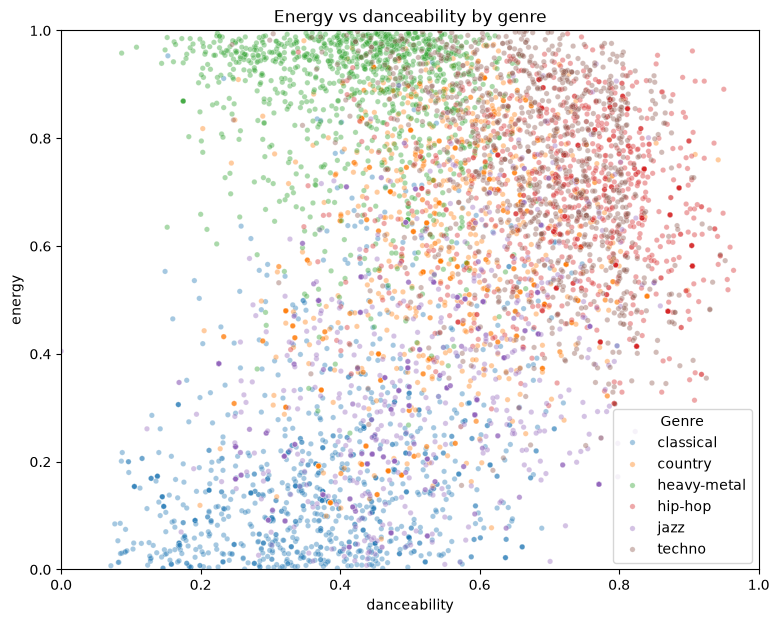

In [22]:
# Energy vs danceability for the six genres, one colour per genre
plot_df = df[df['track_genre'].isin(genres)]

plt.figure(figsize=(9, 7))
sns.scatterplot(data=plot_df, x='danceability', y='energy', hue='track_genre', alpha=0.4, s=15)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.title('Energy vs danceability by genre')
plt.legend(title='Genre')
plt.show()

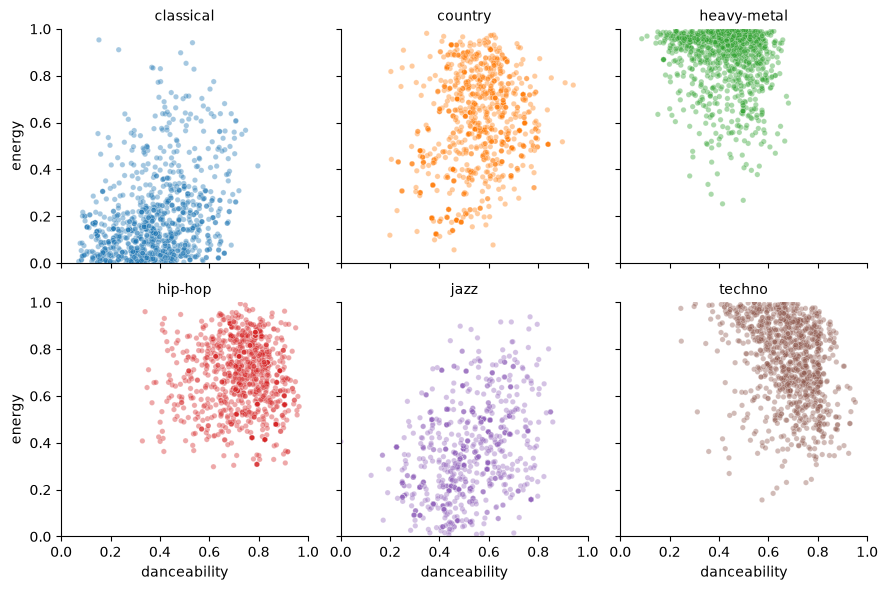

In [23]:
# The same plot with one small plot per genre, so the genres don't hide each other
grid = sns.relplot(data=plot_df, x='danceability', y='energy', col='track_genre', col_wrap=3,
                   hue='track_genre', alpha=0.4, s=15, height=3, legend=False)
grid.set(xlim=(0, 1), ylim=(0, 1))
grid.set_titles('{col_name}')
plt.show()

### Interpretation (Energy vs. Danceability)

From the scatter plots, I can see that the genres have different patterns when comparing energy and danceability.

**Heavy-metal** is at the top of the plot. Almost all heavy-metal songs have an energy close to 1, while the
danceability varies a lot, from about 0.2 to 0.6.

**Classical** is at the bottom left. Most classical songs have a low energy (below 0.3) and a lower
danceability than the other genres.

**Hip-hop** and **techno** are both in the upper right corner, so they are both energetic and danceable.
Techno has a bit higher energy and hip-hop has the highest danceability, but the two groups overlap a lot.

**Jazz** and **country** are in the middle. Jazz is spread out with low to medium energy, and overlaps with
classical at the bottom. Country is spread from about 0.3 to 1.0 in energy, and overlaps with almost every
other genre.

The small plots, one per genre, make this easier to see, since the genres don't cover each other.

What I find interesting is that some genres are easy to separate with only these two features, like classical
and heavy-metal, while others overlap a lot: hip-hop and techno, jazz and classical, and country with almost
everything. So these two features are not enough on their own, and the models will need to combine more features.

## Keeping only the six chosen genres

From here on, the analysis only uses the six genres I chose.

In [24]:
# Keep only the six chosen genres
df = df[df['track_genre'].isin(genres)]

print(f"Rows left: {len(df)}")
print(df['track_genre'].value_counts())

Rows left: 6000
track_genre
classical      1000
country        1000
heavy-metal    1000
hip-hop        1000
jazz           1000
techno         1000
Name: count, dtype: int64


### Interpretation

From the results, I can see that my dataset has been reduced from 114,000 to 6,000 rows.

Each of the six genres still contains exactly 1,000 rows, which means the dataset is still balanced between the different classes.

This is important because no genre has more rows than the others, so the model will not be biased toward a genre simply because it appears more often in the training data.

Now I have a smaller dataset with six different genres, and I can continue with the preprocessing before training my models.

However, I still need to remember that some songs appear in more than one genre, so 6,000 rows does not necessarily mean 6,000 unique songs.

In [25]:
# Re-check the problems found earlier, now only for the six genres
# We found missing values, duplicates and zero tempos earlier.
# Now I want to check if these problems still exist after keeping only six genres.
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Exact duplicate rows: {df.drop(columns='Unnamed: 0').duplicated().sum()}")
print(f"Unique songs: {df['track_id'].nunique()} out of {len(df)} rows")
print(f"Songs with tempo 0: {(df['tempo'] == 0).sum()}")
print(f"Songs with time_signature 0: {(df['time_signature'] == 0).sum()}")

Missing values: 0
Exact duplicate rows: 79
Unique songs: 5910 out of 6000 rows
Songs with tempo 0: 1
Songs with time_signature 0: 1


### Interpretation

Most of the problems from earlier are gone. There are no missing values anymore, since the broken row belonged to a genre I removed.

Some problems are still there, but they are small. There are 79 exact duplicate rows, and 11 songs are listed under two of the six genres. This matches what I found earlier when comparing the genres, where classical and jazz shared 10 songs, while jazz and techno shared 1 song. I also found one song with a tempo of 0 and one with a time signature of 0. These might be the same song, and it could mean that Spotify was unable to detect a clear beat or time signature.

I will handle these problems during preprocessing. The main reason is that duplicates could end up in both the training and test data, or in different folds during cross-validation. Then the model would be tested on a song it has already seen during training, and metrics such as **accuracy, precision, recall and F1-score** would look better than they really are.

However, these checks only find copies with the same `track_id`. Next I check whether the same recording can also hide under a different `track_id`.

#### Re-released recordings

The same recording is often released more than once, for example on an album and later on a
compilation like *"Mozart: A Night of Classics"*. Every release gets its own `track_id` and its own
popularity, so the duplicate checks above can't find these copies. But the audio features are
measured from the sound, so they should be exactly the same. Here I look for songs where all the
audio features are identical to another song.

In [26]:
# The columns that describe the recording itself. popularity, explicit and the names are left out,
# because they can be different for two releases of the same recording.
audio_cols = ['duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
              'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

same_audio = df.duplicated(subset=audio_cols)                    # same sound as an earlier row
same_track = df.duplicated(subset=audio_cols + ['track_id'])     # ... and also the same track_id

print(f"Rows with exactly the same audio as an earlier row: {same_audio.sum()}")
print(f"  of these, with a different track_id (re-releases): {(same_audio & ~same_track).sum()}")

Rows with exactly the same audio as an earlier row: 1339
  of these, with a different track_id (re-releases): 1249


In [27]:
# A few examples: the same recording on different albums, with different track_ids
releases = df.drop_duplicates(subset=audio_cols + ['track_id'])     # ignore the exact copies here
copies = releases[releases.duplicated(subset=audio_cols, keep=False)].sort_values(audio_cols)
copies[['track_id', 'track_name', 'album_name', 'track_genre', 'popularity', 'energy', 'tempo']].head(6)

,track_id,track_name,album_name,track_genre,popularity,energy,tempo
16682,0hzWbtiRS535mA1URdFBNg,"Divertimento No. 11 in D, K.251 ""Nannerl-Septe...",Mozart: A Night of Classics,classical,26,0.1730,116.714
16785,7lRUJ9zBbrOBnz91KOiw0L,"Divertimento No. 11 in D, K.251 ""Nannerl-Septe...",Mozart - All Day Classics,classical,24,0.1730,116.714
16708,5R02WO5PUrHxynXWfheAqN,"12 Variations on an Allegretto in B Flat, K.50...",Mozart: A Night of Classics,classical,24,0.0220,89.780
16814,2mo0DJxh0B6TBGDfK5ZOOa,"12 Variations on an Allegretto in B Flat, K.50...",Mozart - A Classical Dawn,classical,16,0.0220,89.780
16032,0wfvJwWZ1ju6C6ieGQI9hW,"Vom Himmel hoch da komm ich her, BWV 769 - Orc...",Classical Christmas,classical,0,0.0142,95.139
16046,5vFFMf3on3rtVu46VDQJ1T,"Vom Himmel hoch da komm ich her, BWV 769 - Orc...",Klassische Weihnachtsmusik,classical,0,0.0142,95.139


In [28]:
# How many re-released copies does each genre have?
re_releases = df[same_audio & ~same_track]
print(re_releases['track_genre'].value_counts().to_string())

# How many times is the most copied recording in the data?
print(f"\nMost copies of one recording: {df.groupby(audio_cols).size().max()}")

# Share of the groups of identical recordings where all copies have the same track name
groups = df[df.duplicated(subset=audio_cols, keep=False)].groupby(audio_cols)
print(f"Groups where all copies have the same name: {(groups['track_name'].nunique() == 1).mean():.1%}")

track_genre
jazz           487
country        367
hip-hop        244
classical      119
techno          25
heavy-metal      7

Most copies of one recording: 34
Groups where all copies have the same name: 98.5%


### Interpretation

This is a much bigger problem than the exact duplicates. 1,339 rows have exactly the same audio values as an
earlier row, and 1,249 of them have a different `track_id`. These are re-releases: the same recording released
on different albums. The examples show the same Mozart pieces on albums like *Mozart: A Night of Classics* and
*Mozart - All Day Classics*, with exactly the same energy and tempo, but a different popularity.

I am sure that these are copies of the same recording, and not just similar songs. It is very unlikely that two
different songs get exactly the same value for all 13 audio features, and in 98.5% of the groups all the copies
even have the same song name. One recording is in the data 34 times.

The copies are not spread evenly between the genres. Jazz has 487, country 367 and hip-hop 244, while
heavy-metal only has 7. This probably comes from how the dataset was collected, since jazz and country
playlists contain a lot of compilation albums.

This matters for the models. If one copy ends up in the training data and another copy in the test data, the
model is tested on a song it has already seen. I will remove the copies in preprocessing, and keep one copy of
each recording.

## Distributions: Histograms

Here I look at how the values of each audio feature are spread out across all songs.

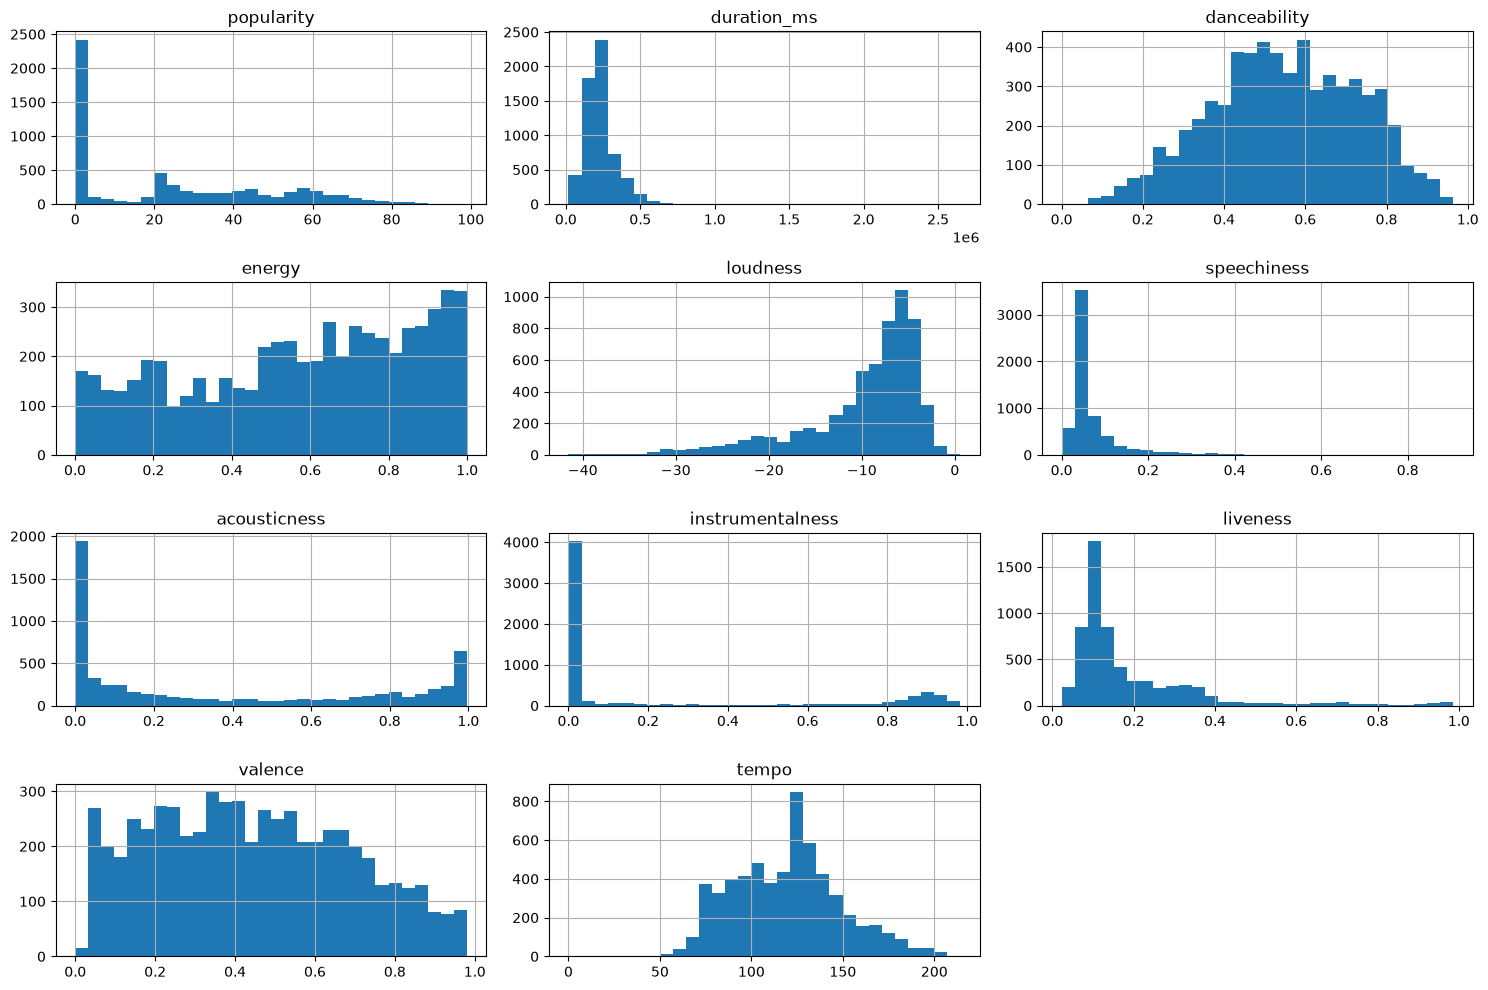

In [29]:
# Histograms of the audio features
plot_features = ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

df[plot_features].hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

### Interpretation

From the histograms, I can see that the audio features are spread out in different ways.

Some features, like `danceability`, `tempo` and `valence`, look roughly bell-shaped. This means 
most songs are somewhere in the middle, and only a few songs have very low or very high values.

Other features are skewed. `speechiness`, `liveness` and `duration_ms` are right-skewed, which 
means most songs have low values, while a small group of songs has much higher values. 
`loudness` and `energy` are the opposite. Here most songs are loud and energetic, and only a 
few songs are very quiet or calm.

The most interesting ones are `acousticness` and `instrumentalness`, because they have two peaks 
instead of one. For `acousticness`, many songs are close to 0 and many are close to 1. This tells 
me there are two groups of songs: some are made with acoustic instruments, and some are more 
electronic. `instrumentalness` shows something similar, where most songs have vocals, but one group 
has almost no vocals at all. Since my goal is to separate genres, I think these two features could 
be very useful, because they seem to split the songs into clear groups.

I decided not to change the skewed features right now. Tree-based models like Decision Tree and 
Random Forest are not affected by the shape of the data, because they only look for a value to 
split on. KNN and neural networks are more sensitive to the size of the values, so I will scale 
the features in preprocessing. I will also test a power transform on the skewed features as one 
of my processing alternatives, and let the tuning show if it actually helps.


I left out `key`, `mode` and `time_signature` because they represent categories rather than continuous measurements. For example, `key` represents musical notes, while `mode` tells us whether a song is in major or minor. A histogram of these values would show how often each category appears, rather than how a continuous feature is distributed.

I also left out `Unnamed: 0` because it is just a row number and does not tell us anything useful about the songs.

I will look at the categorical features separately later, since they need to be interpreted differently.

In [30]:
# Skewness: near 0 = symmetric, positive = long tail to the right, negative = long tail to the left.
# It only describes how lopsided a distribution is, so I use it together with the histograms.
print("Skewness per feature:")
print(df[plot_features].skew().round(3).sort_values().to_string())

Skewness per feature:
loudness           -1.638
energy             -0.348
danceability       -0.134
valence             0.203
tempo               0.275
acousticness        0.486
popularity          0.568
instrumentalness    1.173
liveness            2.463
speechiness         4.300
duration_ms         5.005


### Interpretation

The skewness numbers confirm what the histograms showed. `duration_ms` (5.0) and `speechiness` (4.3)
are the most right-skewed, followed by `liveness` (2.5) and `instrumentalness` (1.2): most songs have
low values, and a few songs have very high values. `loudness` (-1.6) is skewed to the left, since most
songs are loud and only a few are very quiet. `danceability`, `tempo` and `valence` are close to 0,
so they are almost symmetric.

A rule of thumb is that a skewness above 1 or below -1 is strong. Five of the features pass that
limit, so testing a power transform in preprocessing makes sense.

In [31]:
# How many songs have popularity 0, and which genres are they from?
print(f"Songs with popularity 0: {(df['popularity'] == 0).sum()}")
print(df[df['popularity'] == 0]['track_genre'].value_counts())

Songs with popularity 0: 2029
track_genre
jazz           681
country        587
classical      398
hip-hop        289
techno          72
heavy-metal      2
Name: count, dtype: int64


### Interpretation

2029 songs have a popularity of 0. That is about one third of all the songs in my six genres, 
which is a lot.

What stands out is that the zeros are not spread evenly between the genres. Jazz has 681 songs 
with popularity 0, which is more than two thirds of all the jazz songs. Country and classical 
also have many. Heavy metal, on the other hand, only has 2.

A popularity of 0 most likely means that a song has very few or no recent plays on Spotify. 
It says something about how many people listen to the song, not about how the song sounds.

This is a problem for my goal. If I keep `popularity`, the model could learn a shortcut like 
"if popularity is 0, the song is probably jazz or country". That might help the accuracy, but 
it doesn't teach the model anything about what makes a genre sound the way it does. And it 
would not work for a new jazz song that happens to be popular.

Because of this, I am leaning towards dropping `popularity`. Since the assignment asks for 
multiple processing alternatives, I will test both keeping and dropping it in preprocessing. 
At the end I also compare every model with and without it, to see how much of the score comes 
from this shortcut.

##  Outliers

Here I look for songs with values that are far away from the rest. These could be errors in 
the data, or just unusual songs.

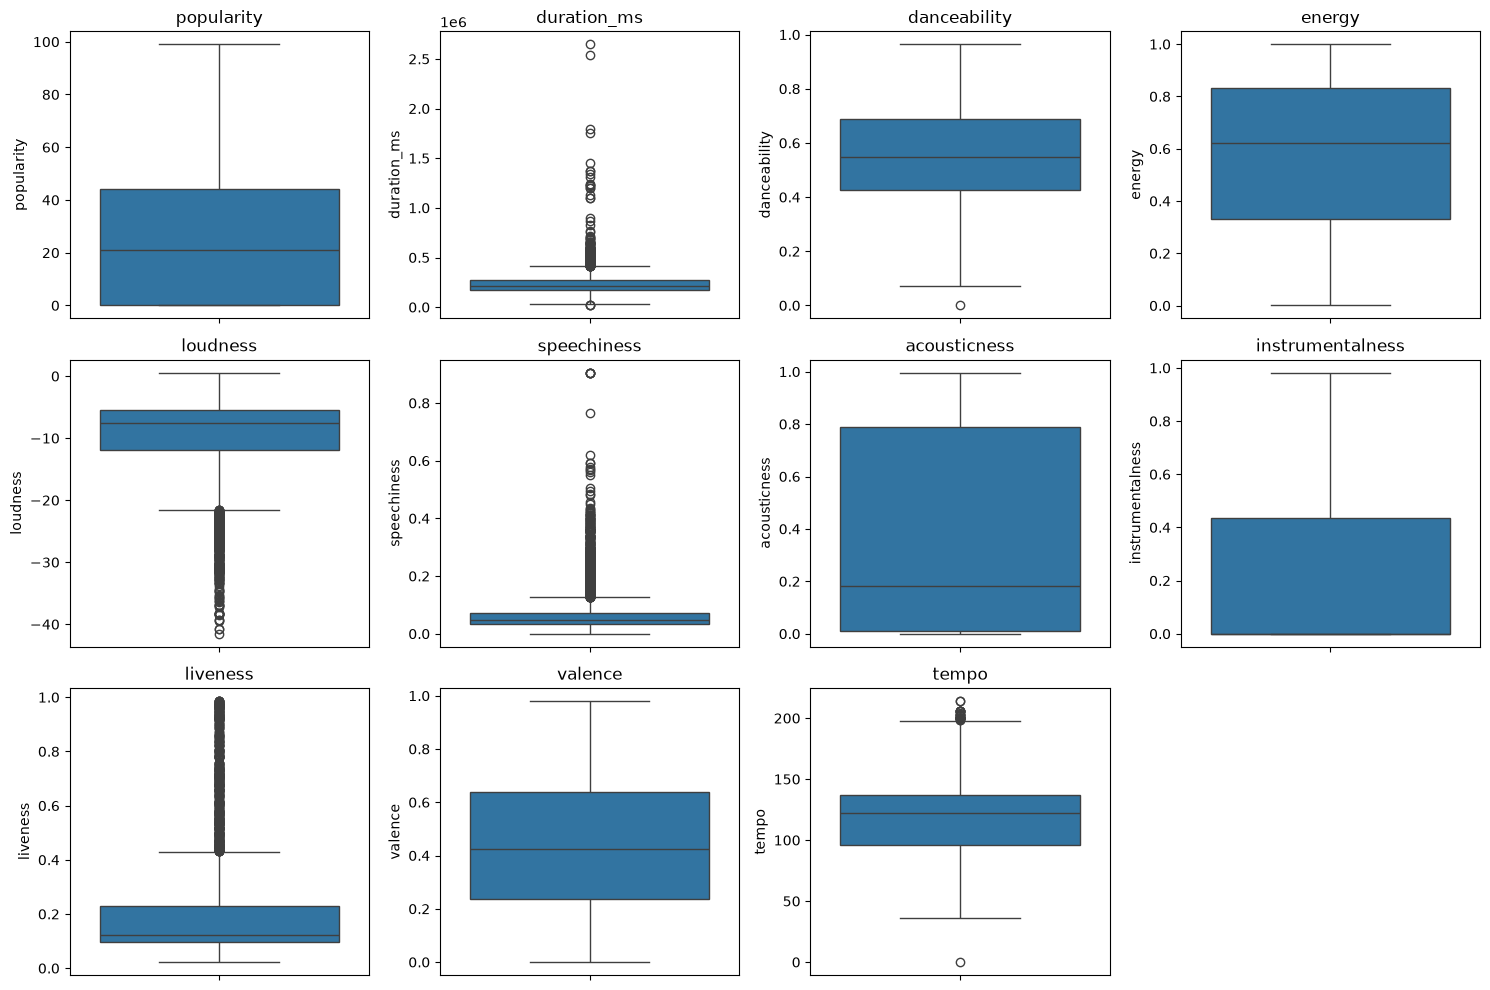

In [32]:
# Box plots of the audio features
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(plot_features):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)

# Hide the empty 12th plot, since there are only 11 features
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [33]:
# Checking exactly how many outliers there are in each column using the IQR method (Interquartile Range).
for col in plot_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    if n_outliers > 0:
        print(f"  {col}: {n_outliers} outliers")
    else:
        print(f"  {col}: no outliers")

  popularity: no outliers
  duration_ms: 382 outliers
  danceability: 1 outliers
  energy: no outliers
  loudness: 442 outliers
  speechiness: 638 outliers
  acousticness: no outliers
  instrumentalness: no outliers
  liveness: 411 outliers
  valence: no outliers
  tempo: 29 outliers


### Interpretation

The features with the most outliers are `speechiness`, `loudness`, `liveness` and `duration_ms`. 
These are the same features that looked skewed in the histograms, so this was expected.

I decided to keep these outliers, because they look like real songs and not errors. 
For example, hip-hop has a lot of rapping, so many hip-hop songs will have a high 
`speechiness`. If I removed these as outliers, I would remove part of what makes hip-hop 
sound different from the other genres, which is exactly what I want the model to learn. 
In the same way, very quiet songs are probably classical or jazz, and the longest songs, 
around 44 minutes, are most likely long classical pieces. Some songs also have a high 
`liveness` because they were recorded live with an audience.

The only outlier I don't trust is the song with a tempo of 0, which also shows up as an outlier 
in `danceability`. This is the song where Spotify couldn't measure a beat, which I found earlier. 
I will remove it in preprocessing.

## Correlation

Here I check which features are related to each other. If two features are very strongly correlated,
they give the model almost the same information.

- Website for reference: https://lost-stats.github.io/Presentation/Figures/heatmap_colored_correlation_matrix.html

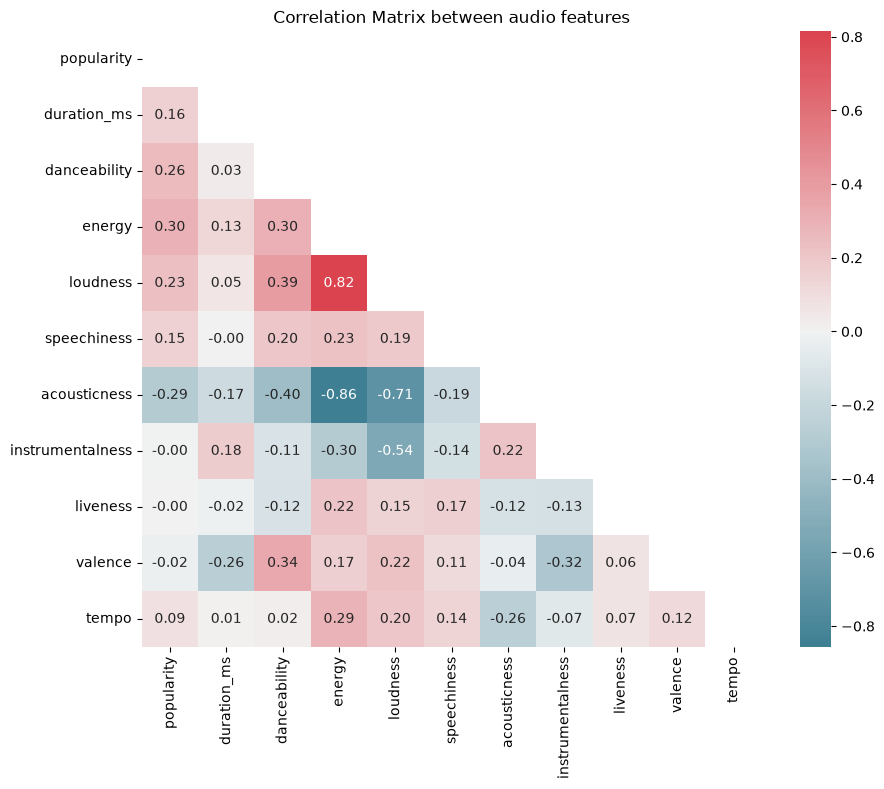

In [34]:
# Correlation between the audio features 

corr = df[plot_features].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(220, 10, as_cmap=True)


plt.figure(figsize=(10,8))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',cmap=cmap,center=0)

plt.title('Correlation Matrix between audio features')

plt.show()

### Interpretation

The strongest relationship is between `energy` and `loudness` (0.76). This makes sense, since loud songs
usually feel energetic. `acousticness` has a strong negative relationship with `energy` (-0.73), and a
moderate negative one with `loudness` (-0.59). This means acoustic songs, like classical or jazz played
on real instruments, tend to be calmer and quieter, while electronic or heavy songs tend to be louder
and more energetic.

There is also a moderate relationship between `valence` and `danceability` (0.48), so happy-sounding
songs tend to be more danceable. `instrumentalness` is negatively related to `loudness` (-0.43) and
`valence` (-0.32), so songs without vocals tend to be quieter and sound less happy.

`popularity` has almost no correlation with the audio features, with values between -0.10 and 0.05.
This supports what I found earlier: popularity differs a lot between the genres (jazz had 681 songs with
popularity 0, heavy-metal only 2), but it is not related to how a song sounds. It measures listeners,
not sound, which is why I test the models both with and without it.

**My decision:** I use a threshold of 0.8. If two features correlate more strongly than that, they give
the model almost the same information, and I would consider dropping one of them. No pair goes above
0.8 (the highest is 0.76), so I keep all the features. Even `energy` and `loudness` measure different
things: a song can be loud without feeling energetic, for example a slow but loud orchestral piece.

## Features vs genre

Here I compare each audio feature across the six genres. If a feature has very different values for
different genres, it should be useful for telling them apart.

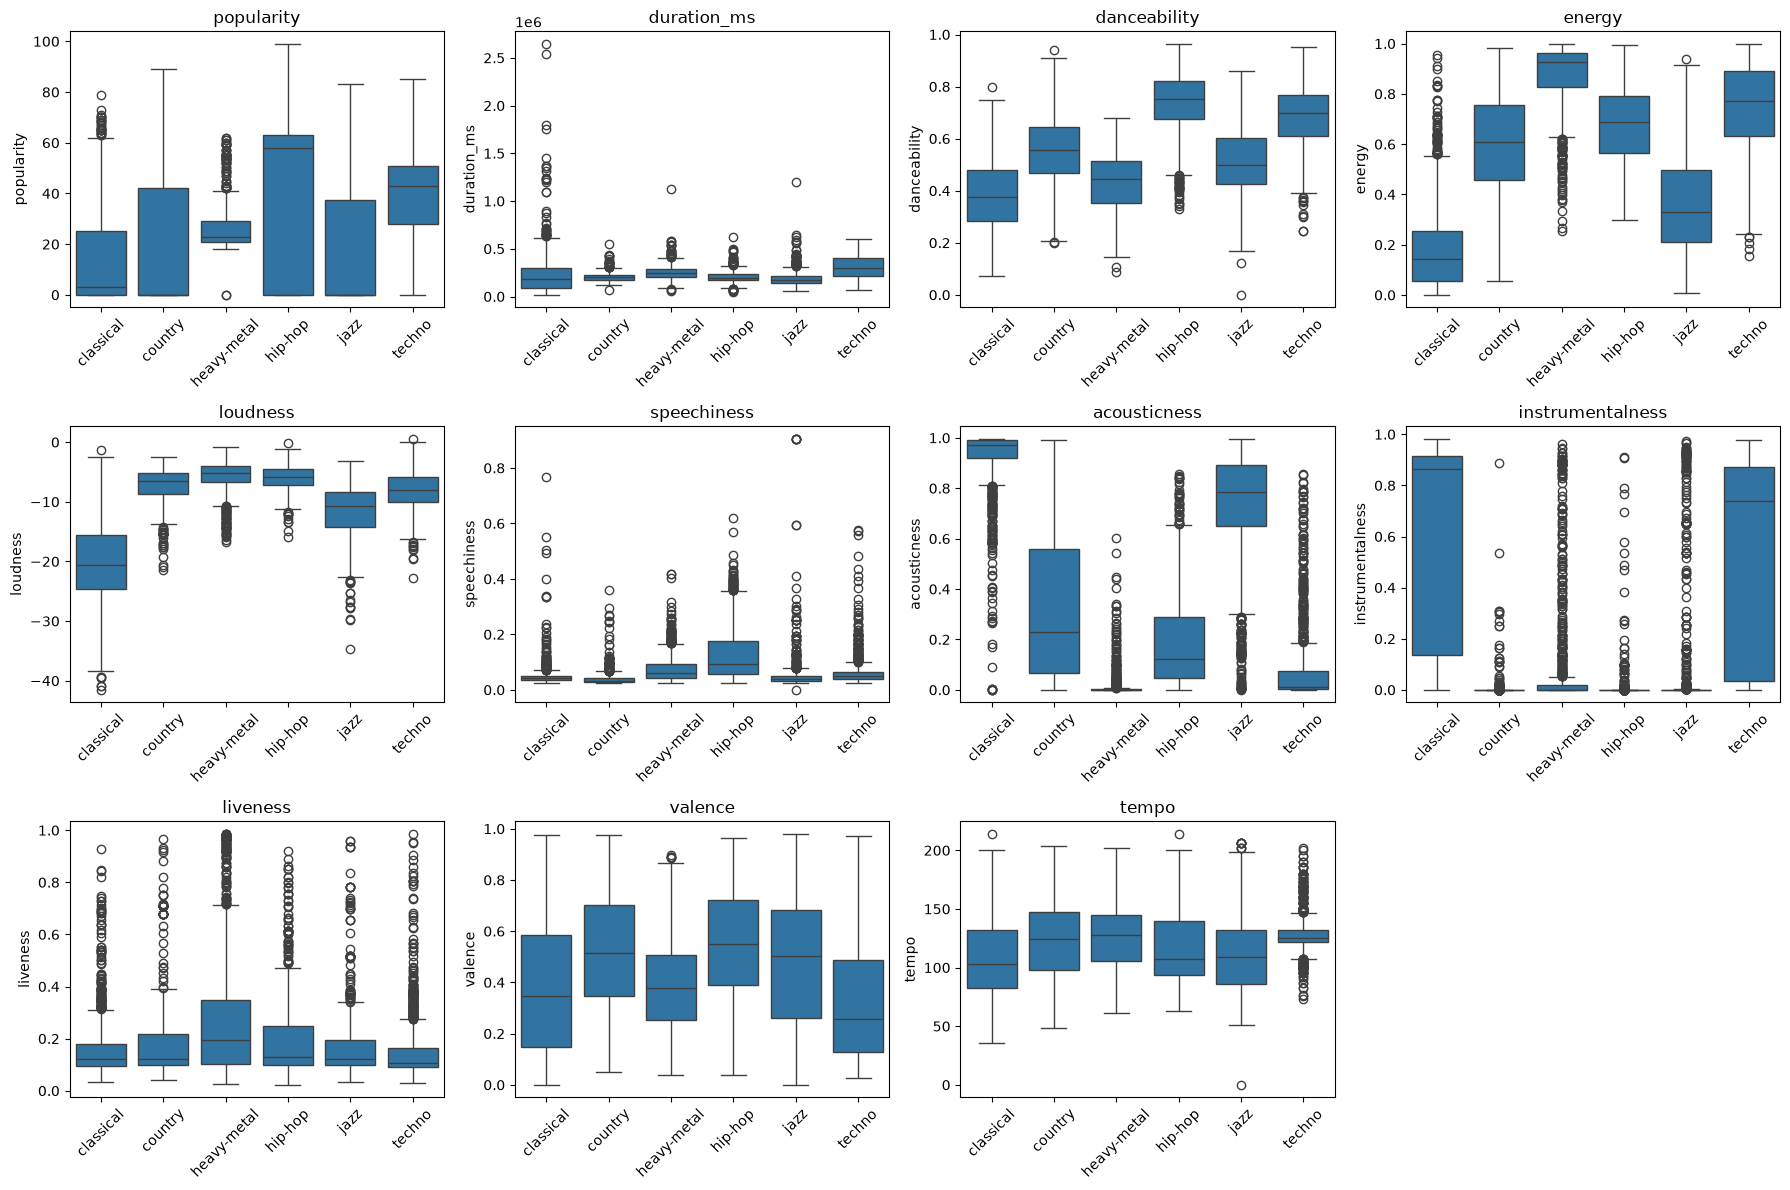

In [35]:
# Box plots of each feature, split by genre
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(plot_features):
    sns.boxplot(data=df, x='track_genre', y=col, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

# Hiding the empty 12th plot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Interpretation

This plot shows clear differences between the genres.

Classical is very quiet and calm, almost fully acoustic, and most songs have no vocals. 
Heavy-metal is the opposite: it is the most energetic and loudest genre, and not acoustic 
at all. Hip-hop is the most danceable genre and has the most speech, which makes sense because 
of the rapping. Techno is energetic and danceable, often without vocals, and almost all 
techno songs have a very similar tempo. Jazz is calm and acoustic like classical, while 
country sits somewhere in the middle on most features.

The features that separate the genres best are `acousticness`, `energy`, `loudness`, 
`instrumentalness` and `danceability`, because the boxes for the different genres are at very 
different heights. `speechiness` mostly helps to recognise hip-hop, and `tempo` mostly helps to 
recognise techno. `liveness` and `duration_ms` look almost the same for every genre, so they 
probably won't help much.

What I find most interesting is how similar genres can still be told apart. Classical and jazz 
are both calm and acoustic, but classical usually has no vocals while jazz does. Heavy-metal and 
techno are both energetic, but techno is more danceable and has fewer vocals. This tells me that 
no single feature can separate all the genres on its own. The models will need to combine several 
features to tell them apart.

## Categorical features 

`explicit`, `mode`, `time_signature` and `key` are categories, not amounts. Here I check how often 
each category appears in each genre, to see if they could help tell the genres apart.

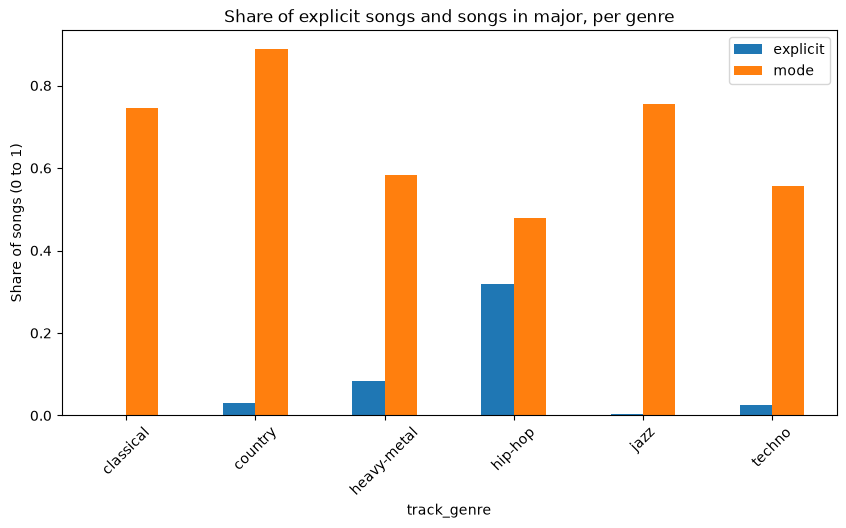

In [36]:
# Share of explicit songs and songs in major, for each genre
share = df.groupby('track_genre')[['explicit', 'mode']].mean()

share.plot(kind='bar', figsize=(10, 5))
plt.title('Share of explicit songs and songs in major, per genre')
plt.ylabel('Share of songs (0 to 1)')
plt.xticks(rotation=45)
plt.show()

### Interpretation

Hip-hop is the only genre with a lot of explicit songs, about 32%. The other genres have very 
few, and classical and jazz have almost none. This means `explicit` can help the model recognise 
hip-hop, but it won't help much to tell the other genres apart.

For `mode`, country has the most songs in major, close to 90%, while hip-hop is about half major 
and half minor. Classical and jazz are mostly in major too, while heavy-metal and techno are more 
mixed. There are some differences, but they are not as big as for features like `acousticness` 
or `energy`.

In [37]:
# How many songs in each genre have each time signature
pd.crosstab(df['track_genre'],df['time_signature'])

time_signature,0,1,3,4,5
track_genre,,,,,
classical,0,42,226,691,41
country,0,1,116,877,6
heavy-metal,0,3,47,945,5
hip-hop,0,11,23,948,18
jazz,1,17,144,807,31
techno,0,3,26,969,2


### Interpretation

Almost every song in every genre has a time signature of 4, which is the most common rhythm in 
music. The main exception is classical and jazz, which have more songs in 3 than the other genres 
(226 and 144). This is the rhythm used in waltzes. Classical also has more songs in 1 and 5, 
which are unusual rhythms.

This means `time_signature` can help a little to recognise classical and jazz, but for the 
other genres it is almost always 4.

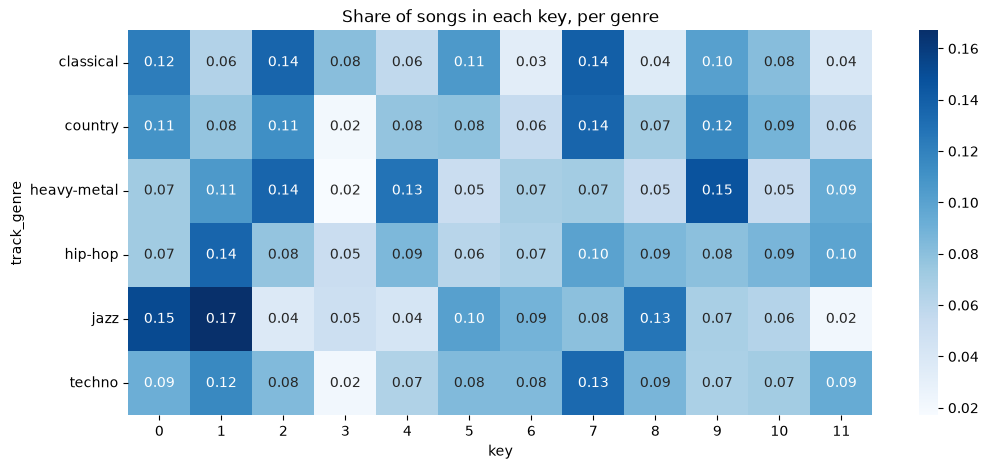

In [38]:
# Share of songs in each key, for each genre
key_share = pd.crosstab(df['track_genre'], df['key'], normalize='index')

plt.figure(figsize=(12, 5))
sns.heatmap(key_share, annot=True, fmt='.2f', cmap='Blues')
plt.title('Share of songs in each key, per genre')
plt.show()

### Interpretation

If songs were spread completely evenly across the 12 keys, each square would be about 0.08, 
since 1 divided by 12 is about 0.08.

Most squares are close to that, but some genres lean towards certain keys. Jazz has more songs 
in key 0 and key 1 (0.15 and 0.17) and very few in key 11 (0.02). Heavy-metal has more songs in 
key 9 (0.15) and key 2 (0.14). Key 3 is rare in almost every genre.

So `key` shows some differences between the genres, but they are smaller than for the audio 
features. It might help the model a little, together with the other features.

## EDA summary

### What I found

**The dataset**
The full dataset has 114,000 songs across 114 genres, with 1,000 songs in each genre. Many genres
share songs. For example, singer-songwriter and songwriter share all 1,000 songs, and pairs like
punk / punk-rock share more than half. A model can't separate genres that contain the same songs,
so I chose six genres that share almost no songs: classical, country, heavy-metal, hip-hop, jazz
and techno. This gives 6,000 songs, perfectly balanced, so a random guess would be right
about 17% of the time.

**Data quality**
In the six genres there are no missing values. There are 79 exact duplicate rows, and 11 songs
are listed under two of my genres. One song has a tempo and time signature of 0, which means
Spotify couldn't measure its beat. The biggest problem is the re-released recordings: 1,249 rows are
copies of another recording with a different `track_id`, mostly in jazz, country and hip-hop.

**The features**
The features that separate the genres best are `acousticness`, `energy`, `loudness`,
`instrumentalness` and `danceability`. `speechiness` and `explicit` mostly help to recognise
hip-hop, and `tempo` mostly helps to recognise techno. `time_signature` helps a little for
classical and jazz. `liveness` and `duration_ms` look almost the same for every genre.

No single feature separates all six genres. For example, classical and jazz are both calm and
acoustic, but classical usually has no vocals while jazz does. The models will need to combine
several features.

`popularity` has no relationship with any of the audio features, and a third of the songs have a
popularity of 0, mostly in jazz, country and classical. It says something about listeners, not
about how a song sounds.

### My decisions for preprocessing

| What | Decision | Why |
|---|---|---|
| `Unnamed: 0`, `track_id` | Drop | Just a row number and an ID, they say nothing about the music. I use `track_id` to find duplicates first |
| `artists`, `album_name`, `track_name` | Drop | Names, not sound. They could let the model learn who made a song instead of how it sounds |
| Exact duplicates | Remove | They could end up in both training and test data |
| Songs in two genres | Remove | The same song with two different labels confuses the model |
| Re-released copies | Remove, keep one copy | The same recording could end up in both training and test data |
| Song with tempo 0 | Remove | The value is missing, not real |
| Outliers | Keep | They are real songs, and they are often what makes a genre different |
| `popularity` | Test both keeping and dropping | It may help the score, but it is not about the sound. I compare both at the end |
| Skewed features | Test with and without a power transform | Some models are sensitive to skew, others are not |
| Correlated features | Keep all | No pair goes above my threshold of 0.8 |
| `explicit` | Turn into 1/0 | It is True/False |
| `key`, `time_signature` | Test one-hot encoding and keeping them as numbers | A higher number does not mean "more", but trees can still split on them |
| Scaling | Test different scalers | KNN and neural networks need features on the same scale |

**Scaling:** Some numerical features have very different ranges. For example, energy ranges from 0 to 1,
while duration is measured in thousands of milliseconds. This affects distance-based models such as KNN and
the neural networks, so I test different ways of scaling the numerical features during preprocessing.

# PREPROCESSING

In this part I carry out the decisions from the EDA summary. First I clean the data, 
then I prepare the features and the label for the models.

##  Cleaning

In [39]:
# Drop the row number column first. It makes every row unique, so duplicates can't be found while it's there.
# errors='ignore' means: if the column is already gone, just continue instead of crashing.
df = df.drop(columns='Unnamed: 0', errors='ignore')

# Remove exact duplicate rows
df = df.drop_duplicates()
print(f"Rows after removing exact duplicates: {len(df)}")

Rows after removing exact duplicates: 5921


In [40]:
# Find songs that are listed under more than one genre
genres_per_song = df.groupby('track_id')['track_genre'].nunique()
songs_in_two_genres = genres_per_song[genres_per_song > 1].index

# Remove all copies of those songs, since we can't know which genre is the right one
df = df[~df['track_id'].isin(songs_in_two_genres)]
print(f"Songs listed under two genres: {len(songs_in_two_genres)}")
print(f"Rows left: {len(df)}")

Songs listed under two genres: 11
Rows left: 5899


In [41]:
# Remove re-released copies: keep one copy of every recording, based on the audio features only.
# I save the data before this step, so I can show afterwards how much the copies would have mattered.
df_with_copies = df.copy()

df = df.drop_duplicates(subset=audio_cols)
print(f"Re-released copies removed: {len(df_with_copies) - len(df)}")
print(f"Rows left: {len(df)}")

Re-released copies removed: 1248
Rows left: 4651


In [42]:
# Remove songs where Spotify couldn't measure a tempo
df = df[df['tempo'] != 0]
print(f"Rows left: {len(df)}")
print(df['track_genre'].value_counts())

Rows left: 4650
track_genre
heavy-metal    991
techno         974
classical      805
hip-hop        747
country        633
jazz           500
Name: count, dtype: int64


### Interpretation

After cleaning, 4,650 songs are left. Most of the removed rows were re-released copies (1,248). The rest were
exact duplicates (79), songs listed under two genres (22 rows from 11 songs) and the song with a tempo of 0.

Removing the copies changed the balance between the genres a lot. Heavy-metal (991) and techno (974) kept
almost all their songs, but jazz went down to 500 and country to 633. So the dataset is no longer balanced:
heavy-metal now has about twice as many songs as jazz.

I still think removing the copies is the right choice, because a model that is tested on copies of its training
songs gives results that are too good (I show how much below). But the imbalance has some consequences for the
rest of the project:

- I use a stratified split, so every genre has the same share in the training and test data.
- I use the macro average for precision, recall and F1, which gives every genre the same weight. Accuracy alone
  would favour the big genres.
- For the tree models I tune `class_weight` (`None` or `'balanced'`), which can give the smaller genres more
  weight during training, like I did in my first project.
- A random guess is no longer exactly 1/6, so I measure it with a `DummyClassifier` before the real models.

### How much would the re-released copies have mattered?

To see why removing the copies is important, I repeat the split on the data that still has the
copies and train one Gradient Boosting model with default settings. Then I compare two groups of
test songs: songs that have an identical copy in the training data, and songs that are truly new.

In [43]:
# The data before the copies were removed (without the tempo 0 song), split the same way as below
leaky = df_with_copies[df_with_copies['tempo'] != 0]
leaky_train = leaky.groupby('track_genre').sample(frac=0.8, random_state=random_state)
leaky_test = leaky.drop(leaky_train.index)

# A test song is "already seen" if a song with exactly the same audio values is in the training data
train_recordings = set(leaky_train[audio_cols].apply(tuple, axis=1))
already_seen = leaky_test[audio_cols].apply(tuple, axis=1).isin(train_recordings).to_numpy()
print(f"Test songs with an identical copy in the training data: {already_seen.sum()} of "
      f"{len(leaky_test)} ({already_seen.mean():.1%})")

# One Gradient Boosting model with default settings
input_cols = audio_cols + ['popularity']
leaky_model = HistGradientBoostingClassifier(random_state=random_state)
leaky_model.fit(leaky_train[input_cols], leaky_train['track_genre'])
leaky_pred = leaky_model.predict(leaky_test[input_cols])

true_genres = leaky_test['track_genre'].to_numpy()
print(f"\nMacro F1, all test songs:     {f1_score(true_genres, leaky_pred, average='macro'):.3f}")
print(f"Macro F1, already seen songs: {f1_score(true_genres[already_seen], leaky_pred[already_seen], average='macro'):.3f}")
print(f"Macro F1, truly new songs:    {f1_score(true_genres[~already_seen], leaky_pred[~already_seen], average='macro'):.3f}")

Test songs with an identical copy in the training data: 305 of 1180 (25.8%)



Macro F1, all test songs:     0.926
Macro F1, already seen songs: 1.000
Macro F1, truly new songs:    0.884


### Interpretation

Without removing the copies, 305 of the 1,180 test songs (25.8%) would have an identical copy in the
training data. That is about one in four test songs.

The model gets a macro F1 of 1.000 on these songs: every single one is correct, because the model has already
seen exactly the same values with the right genre. On the truly new songs, the F1 is only 0.884. All together
the score would have been 0.926, which looks better than what the model can actually do on new songs.

This is exactly the kind of data leakage I wanted to avoid, and the same thing would happen inside the
cross-validation, so the tuning would also be too optimistic. With the copies removed, the scores in the rest of
the notebook are lower than in my first version, but they are honest: they show how well the models do on songs
they have really never seen.

##  Dropping columns

Here I drop the columns that don't describe how a song sounds.

In [44]:
# Keep the song names in a separate table, so I can look up the songs the models get wrong at the end
song_info = df[['track_name', 'artists', 'album_name']].copy()

# Drop columns that are names or IDs, not audio features.
# track_id is dropped now, since I'm done using it to find duplicates.
df = df.drop(columns=['track_id', 'artists', 'album_name', 'track_name'])

print(f"Columns left: {list(df.columns)}")

Columns left: ['popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


## Encoding

Models need numbers. Here I turn `explicit` into numbers, and separate the features from the label.

In [45]:
# explicit is True/False. Turn it into 1/0 so the models can use it.
df['explicit'] = df['explicit'].astype(int)
print(df['explicit'].value_counts())

explicit
0    4320
1     330
Name: count, dtype: int64


In [46]:
# Separate the features (input) from the label (what we want to predict)
features = df.drop(columns='track_genre')
targets = df['track_genre']

print(f"Features: {features.shape[1]} columns")
print(f"Targets: {targets.nunique()} genres")

Features: 15 columns
Targets: 6 genres


In [47]:
# Turn the genre names into numbers 0 to 5
label_encoder = LabelEncoder()
targets = pd.Series(label_encoder.fit_transform(df['track_genre']), index=df.index)

# Show which number belongs to which genre
for number, genre in enumerate(label_encoder.classes_):
    print(f"{number} = {genre}")

0 = classical
1 = country
2 = heavy-metal
3 = hip-hop
4 = jazz
5 = techno


### Interpretation

`explicit` is now 1/0 instead of True/False. The genre names are turned into numbers from 0 to 5 
with `LabelEncoder`. The numbers are just labels and don't mean that one genre is "more" than 
another. I keep the encoder so I can turn the numbers back into genre names later, for example 
on the confusion matrices.

I don't encode `key` and `time_signature` here, because I want to test two ways of handling them. 
That choice is part of the pipeline later.

## Train/test split

I split the data into a training set and a test set. The models learn from the training set,
and the test set is only used once at the very end, to see how well they do on songs they have
never seen.

Unlike in my first project, I don't need a separate validation set. The hyperparameter tuning uses
cross-validation, which creates its own validation folds from the training data. I create the folds
once with `StratifiedKFold`, and give the same folds to every model. That way all the models are
tuned and compared on exactly the same data.

In [48]:
# Stratified split: 80% train, 20% test.
# Sampling 80% from each genre separately keeps the same share of every genre in both sets.
train_indices = df.groupby('track_genre').sample(frac=0.8, random_state=random_state).index
test_indices = df.drop(train_indices).index

# The sampled rows come out sorted by genre. I shuffle the training set once, so the order of the
# rows has nothing to do with the genre. (Keras uses the last 10% of its training data for early
# stopping, so without shuffling that part could contain only one genre.)
train_features = features.loc[train_indices].sample(frac=1, random_state=random_state)
train_targets = targets.loc[train_features.index]

test_features = features.loc[test_indices]
test_targets = targets.loc[test_indices]

# The same 5 folds are used for the tuning of every model.
# shuffle=True mixes the songs before they are divided into folds.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

print(f"Training songs: {len(train_features)}, test songs: {len(test_features)}\n")

# Checking that every genre has the same share in both sets
shares = pd.DataFrame({'train': train_targets.value_counts(normalize=True),
                       'test': test_targets.value_counts(normalize=True)})
shares.index = label_encoder.classes_[shares.index]
print(shares.round(3))

Training songs: 3720, test songs: 930

             train   test
heavy-metal  0.213  0.213
techno       0.209  0.210
classical    0.173  0.173
hip-hop      0.161  0.160
country      0.136  0.137
jazz         0.108  0.108


### Interpretation

The data is split into 3,720 training songs and 930 test songs. Each genre has almost exactly the same share in
both sets, so the split is stratified as intended. The table also shows the imbalance from the cleaning:
heavy-metal is 21.3% of the songs, while jazz is only 10.8%.

This means the test set is a fair representation of the training set, and no genre is over- or under-represented
when I evaluate the models.

##  Pipeline and processing alternatives

Instead of choosing one way to process the data, I set up several alternatives and let the 
automated tuning compare them. I use a `Pipeline` with a `ColumnTransformer`, following the 
approach from the course workshop.

A pipeline also prevents data leakage. During cross-validation, the processing (for example the 
scaling) is learned only from the training folds, and then applied to the validation fold.

The alternatives come from my EDA:
- **Skewed features:** with or without a `PowerTransformer` (Yeo-Johnson)
- **Scaling:** no scaling, `StandardScaler` or `MinMaxScaler`
- **popularity:** keep or drop
- **key and time_signature:** one-hot encoding or keep them as numbers

The trees (Decision Tree and the three tree ensembles) only get the `popularity` and encoding
alternatives. Scaling or a power transform doesn't change a tree: it only changes the numbers, not
the order of the songs, so the tree finds exactly the same splits. KNN and the neural networks get
all the alternatives, since they work with distances and sizes of values.

In [49]:
# Group the columns by how they should be processed
numeric_features = ['duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
                    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

categorical_features = ['key', 'time_signature']
binary_features = ['explicit', 'mode']

## Preprocessor

The preprocessor describes how each group of columns is processed before the model sees it. 
Before this step I only did things that follow a fixed rule and don't depend on the data: 
cleaning, `explicit` to 1/0 and the genre label. Everything that learns from the data 
(scaling, power transform, one-hot encoding) is defined here.

Nothing is processed yet. This only defines the steps. The values are calculated when the pipeline 
is fitted inside `GridSearchCV`, so the mean and standard deviation come from the training folds only.
I make it a function so every model gets its own fresh copy.

`StandardScaler` subtracts the mean and divides by the standard deviation for each column, the same 
formula as the mean normalization in my first project. KNN and neural networks need it. Trees don't.

In [50]:
# Build the preprocessing step. Each part below is a default, and the grid search can swap it
# for one of the alternatives.
def make_preprocessor():
    return ColumnTransformer([
        # Numeric features: first an optional power transform, then scaling
        ('numeric', Pipeline([
            ('power', 'passthrough'),
            ('scale', StandardScaler())
        ]), numeric_features),

        # popularity on its own, so it can be kept (scaled) or dropped
        ('popularity', StandardScaler(), ['popularity']),

        # key and time_signature: one-hot encoded by default.
        # handle_unknown='ignore' avoids errors if a rare value only appears in one fold
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),

        # explicit and mode are already 0/1
        ('binary', 'passthrough', binary_features)
    ])

# MODELS

I train two baseline models, three ensemble models and two neural networks, plus a stacking ensemble
as an extra. Each model is tuned automatically with `GridSearchCV` or `RandomizedSearchCV`, using the
same 5 cross-validation folds. The processing alternatives are tuned together with the model
parameters. I use the macro F1 score to compare settings, so every genre counts equally.

After tuning, the search automatically refits the best settings on the whole training set. The test
set is not used in this part at all. All the models are tested together in the evaluation part.

For every model I show:
- the best settings and the best cross-validation score
- the best score for every value of every tuned parameter (`summarize_results`)
- the mean score and the spread over the 5 folds (`show_score`)
- a plot of the average score for every value of every parameter (`plot_search`)

In [51]:
# Short names for the processing objects, so the tables and plots are easier to read
def short_name(value):
    names = {"OneHotEncoder(handle_unknown='ignore')": 'one-hot',
             'StandardScaler()': 'StandardScaler',
             'MinMaxScaler()': 'MinMaxScaler',
             'PowerTransformer()': 'PowerTransformer'}
    return names.get(str(value), str(value))


# Puts parameter values in a natural order: numbers from small to large first, then text
def value_order(labels):
    def key(label):
        try:
            return (0, float(label), '')
        except ValueError:
            return (1, 0, label)
    return sorted(set(labels), key=key)


# Prints the best cross-validation score for every value of every tuned parameter.
def summarize_results(search):
    cv_results = pd.DataFrame(search.cv_results_)
    for col in cv_results.columns:
        if col.startswith('param_'):
            # fillna('None') makes sure max_depth=None is included in the table
            values = cv_results[col].fillna('None').map(short_name)
            best_per_value = cv_results.groupby(values)['mean_test_score'].max()
            best_per_value = best_per_value.reindex(value_order(best_per_value.index)).rename_axis(None)
            print(f"\n{col.replace('param_', '')}:")
            print(best_per_value.round(3).to_string())


# Prints the mean score and the spread over the 5 folds for the best settings of one search
def show_score(name, search):
    best = pd.DataFrame(search.cv_results_).loc[search.best_index_]
    print(f"\n{name}: {best['mean_test_score']:.3f} ± {best['std_test_score']:.3f}")


# One bar plot per tuned parameter. Each bar is the AVERAGE score over all the other settings
# (summarize_results shows the BEST score), so the plots show how much a parameter matters in general.
def plot_search(search, ncols=3):
    results = pd.DataFrame(search.cv_results_)
    params = [col for col in results.columns if col.startswith('param_')]
    nrows = int(np.ceil(len(params) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
    axes = np.array(axes).flatten()
    low, high = results['mean_test_score'].min(), results['mean_test_score'].max()
    for ax, col in zip(axes, params):
        values = results[col].fillna('None').map(short_name)
        sns.barplot(x=values, y=results['mean_test_score'], order=value_order(values), ax=ax,
                    color='steelblue', errorbar=None)
        ax.set_title(col.replace('param_', ''))
        ax.set_xlabel('')
        ax.set_ylabel('mean CV macro F1')
        ax.set_ylim(low - 0.02, high + 0.01)    # zoomed in so small differences are visible
        ax.tick_params(axis='x', rotation=20)
    for ax in axes[len(params):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

## Reference: random guessing

Before the real models, I measure what random guessing scores. `DummyClassifier` with
`strategy='uniform'` picks a random genre for every song. Every real model has to beat this.

In [52]:
dummy = DummyClassifier(strategy='uniform', random_state=random_state)
dummy_scores = cross_val_score(dummy, train_features, train_targets, cv=cv, scoring='f1_macro')
print(f"Random guessing, macro F1: {dummy_scores.mean():.3f} ± {dummy_scores.std():.3f}")

# Fitted on the training data for the test comparison later
dummy.fit(train_features, train_targets);

Random guessing, macro F1: 0.162 ± 0.009


### Interpretation

Random guessing gets a macro F1 of 0.162 ± 0.009. This is close to 1/6 ≈ 0.17, which makes sense for six genres.
This is the score every model has to beat.

## Baseline: Decision Tree

A decision tree asks a series of yes/no questions about the features, for example
"is acousticness above 0.8?", and ends in a leaf with a genre. It is easy to understand, but a deep
tree can memorize the training data, so `max_depth` and `min_samples_leaf` are important to tune.

In [53]:
dt_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', DecisionTreeClassifier(random_state=random_state))
])

dt_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__max_depth': [4, 8, 12, 16, None],
    'estimator__min_samples_leaf': [1, 5, 10],
    'estimator__criterion': ['gini', 'entropy'],
    'estimator__class_weight': [None, 'balanced']     # give the smaller genres more weight or not
}

dt_grid = GridSearchCV(dt_pipe, dt_params, cv=cv, scoring='f1_macro', n_jobs=-1)
dt_grid.fit(train_features, train_targets)

print(f"Best settings: {dt_grid.best_params_}")
print(f"Best cross-validation F1: {dt_grid.best_score_:.3f}")

Best settings: {'estimator__class_weight': None, 'estimator__criterion': 'entropy', 'estimator__max_depth': 16, 'estimator__min_samples_leaf': 5, 'preprocess__categorical': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.779



estimator__class_weight:
None        0.779
balanced    0.767

estimator__criterion:
entropy    0.779
gini       0.772

estimator__max_depth:
4       0.685
8       0.772
12      0.776
16      0.779
None    0.779

estimator__min_samples_leaf:
1     0.772
5     0.779
10    0.766

preprocess__categorical:
one-hot        0.776
passthrough    0.779

preprocess__popularity:
StandardScaler    0.779
drop              0.726

Decision Tree: 0.779 ± 0.007


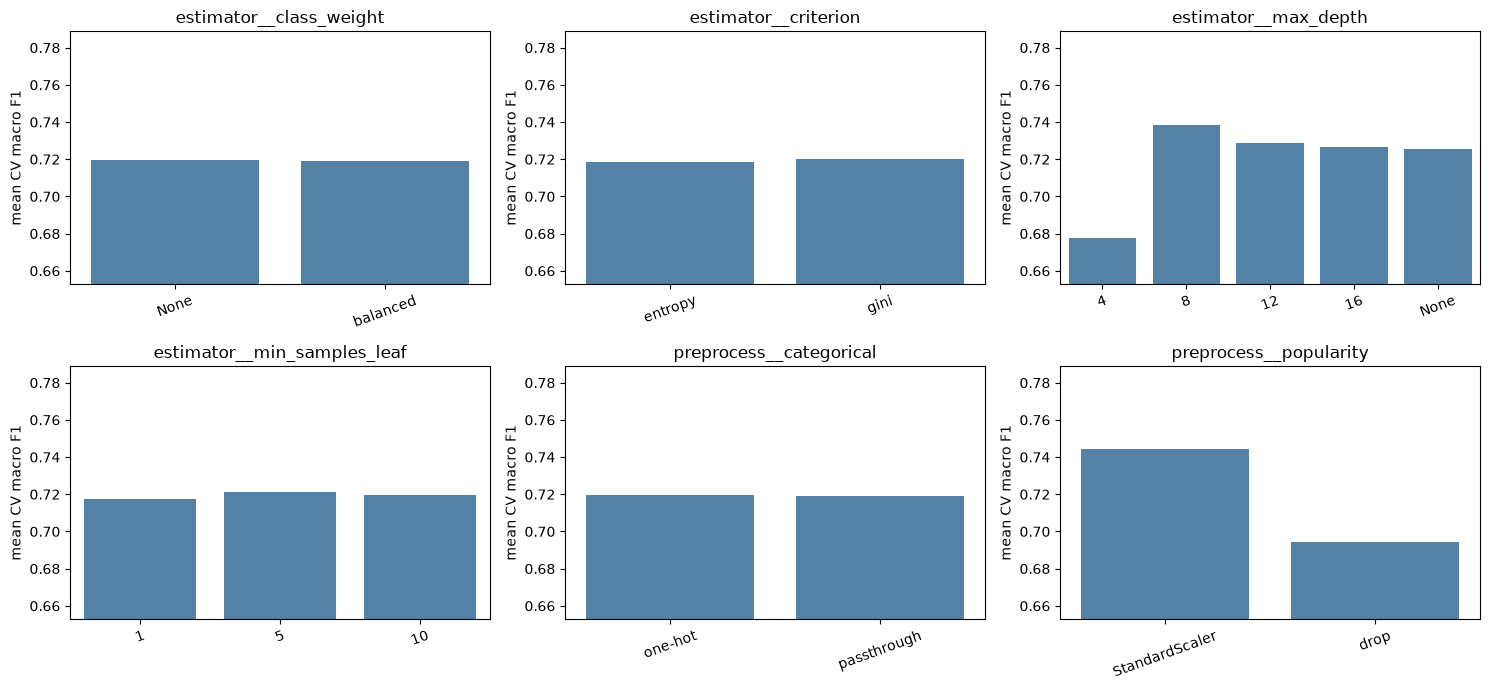

In [54]:
summarize_results(dt_grid)
show_score('Decision Tree', dt_grid)
plot_search(dt_grid)

### Interpretation

The best Decision Tree reaches a macro F1 of 0.779 ± 0.007 in cross-validation. This is far above random
guessing (0.162), but it is the lowest of all my models.

The best settings are `max_depth=16`, `min_samples_leaf=5` and `entropy`, without class weights. For `max_depth`,
the score jumps from 0.685 at depth 4 to 0.772 at depth 8, and then levels out: depth 16 and no limit both give
0.779. So the range I tested is wide enough, and a deeper tree doesn't help. For `min_samples_leaf`, 5 is in the
middle of the range and works best, so forcing every leaf to contain at least 5 songs helps the tree a little
against overfitting. `gini` and `entropy` give almost the same result (0.772 and 0.779).

`class_weight='balanced'` doesn't help here (0.767 vs 0.779). Keeping `key` and `time_signature` as numbers is
slightly better than one-hot encoding (0.779 vs 0.776). This makes sense for a tree, since it can split directly
on a number, while one-hot encoding spreads `key` over 12 separate columns.

Keeping `popularity` gives the biggest improvement of all the settings, from 0.726 to 0.779. I still think part
of this comes from a shortcut, since jazz and country have many songs with popularity 0. I look closer at this in
the further analysis.

## Baseline : K-Nearest Neighbors (KNN)

KNN predicts the genre of a song by looking at the most similar songs in the training data. 
Since it measures distances between songs, it is sensitive to the scale of the features. 
This is where the scaling and power transform alternatives matter most.

In [55]:
knn_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', KNeighborsClassifier())
])

knn_params = {
    # Processing alternatives
    'preprocess__numeric__power': ['passthrough', PowerTransformer()],
    'preprocess__numeric__scale': ['passthrough', StandardScaler(), MinMaxScaler()],
    'preprocess__popularity': ['drop', StandardScaler()],
    # Model parameters
    'estimator__n_neighbors': [5, 11, 21, 31, 51, 75, 101],
    'estimator__weights': ['uniform', 'distance'],
    'estimator__p': [1, 2]
}

knn_grid = GridSearchCV(knn_pipe, knn_params, cv=cv, scoring='f1_macro', n_jobs=-1)
knn_grid.fit(train_features, train_targets)

print(f"Best settings: {knn_grid.best_params_}")
print(f"Best cross-validation F1: {knn_grid.best_score_:.3f}")

Best settings: {'estimator__n_neighbors': 11, 'estimator__p': 1, 'estimator__weights': 'distance', 'preprocess__numeric__power': PowerTransformer(), 'preprocess__numeric__scale': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.793



estimator__n_neighbors:
5      0.779
11     0.793
21     0.791
31     0.787
51     0.776
75     0.775
101    0.765

estimator__p:
1    0.793
2    0.776

estimator__weights:
distance    0.793
uniform     0.785

preprocess__numeric__power:
PowerTransformer    0.793
passthrough         0.783

preprocess__numeric__scale:
MinMaxScaler      0.750
StandardScaler    0.793
passthrough       0.793

preprocess__popularity:
StandardScaler    0.793
drop              0.754

KNN: 0.793 ± 0.011


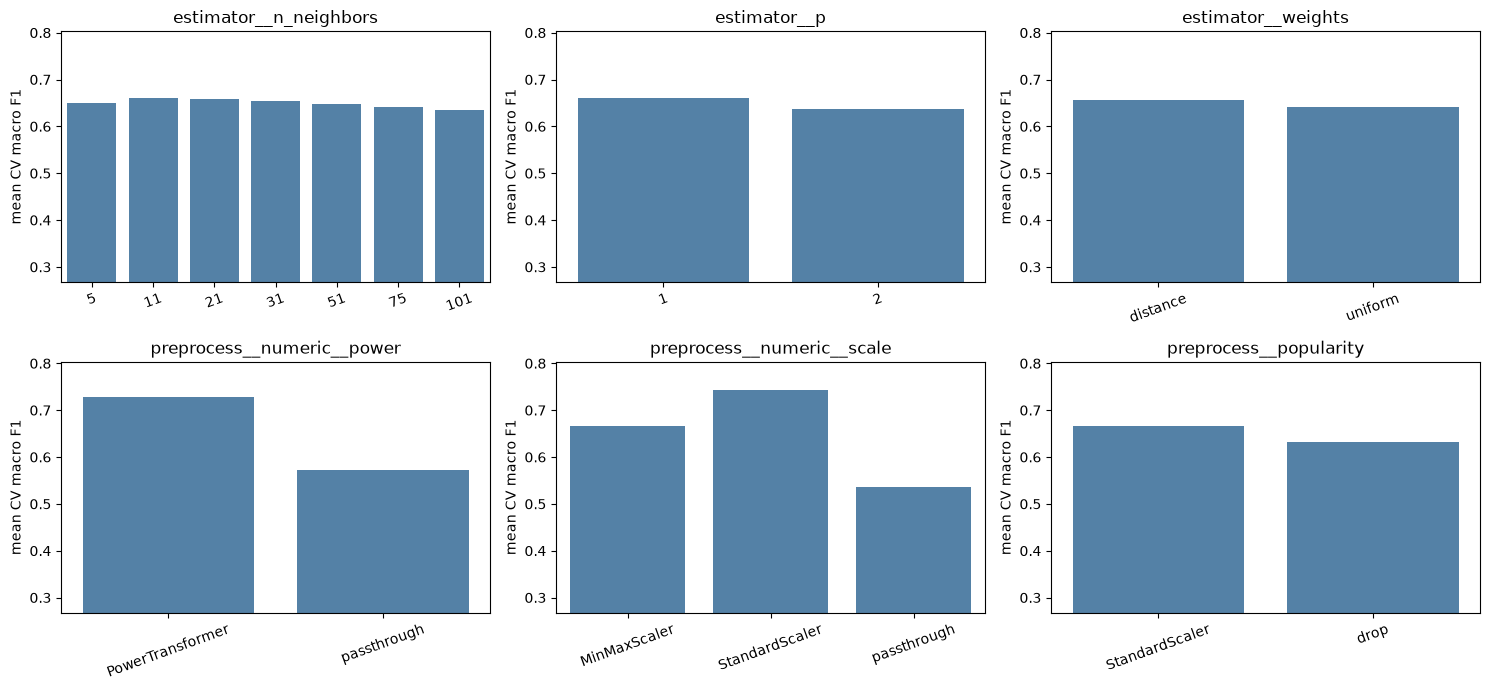

In [56]:
summarize_results(knn_grid)
show_score('KNN', knn_grid)
plot_search(knn_grid)

### Interpretation

The best KNN reaches a macro F1 of 0.793 ± 0.011, a bit better than the Decision Tree (0.779).

The best number of neighbours is 11, which is in the middle of the range I tested (5 to 101). With 5 neighbours
the score is lower (0.779), because the vote depends on very few songs. From 21 neighbours and up it slowly drops
(0.765 at 101), because songs that are far away also get a vote. So the range is wide enough.

The plots show that the processing matters much more for KNN than the model settings. Without any scaling, the
average score is only about 0.54, compared to about 0.74 with `StandardScaler`, because features with large values
like `duration_ms` dominate the distance between songs. The `PowerTransformer` also helps a lot on average (about
0.73 vs 0.57), which fits with the skewed features I found in the EDA. This confirms what I expected.

The best combination uses the `PowerTransformer` without an extra scaler. This looks strange at first, but the
`PowerTransformer` already standardizes the values by default, so the data is still scaled. With `StandardScaler`
after it, the score is the same (0.793).

Giving closer songs a bigger vote (`distance`) works better than giving every neighbour the same vote (0.793 vs
0.785), and Manhattan distance (p=1) works better than Euclidean distance (0.793 vs 0.776). Keeping `popularity`
improves the score from 0.754 to 0.793.

## Ensemble : Random Forest

A Random Forest trains many decision trees, each on a random part of the data and with a random 
selection of features. The final prediction is a vote between all the trees. Combining many trees 
usually reduces overfitting compared to a single tree.

In [57]:
rf_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', RandomForestClassifier(random_state=random_state))
])

rf_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__n_estimators': [100, 300],
    'estimator__max_depth': [10, 20, None],
    'estimator__max_features': ['sqrt', 'log2'],
    'estimator__class_weight': [None, 'balanced']
}

rf_grid = GridSearchCV(rf_pipe, rf_params, cv=cv, scoring='f1_macro', n_jobs=-1)
rf_grid.fit(train_features, train_targets)

print(f"Best settings: {rf_grid.best_params_}")
print(f"Best cross-validation F1: {rf_grid.best_score_:.3f}")

Best settings: {'estimator__class_weight': 'balanced', 'estimator__max_depth': 20, 'estimator__max_features': 'sqrt', 'estimator__n_estimators': 300, 'preprocess__categorical': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.850



estimator__class_weight:
None        0.843
balanced    0.850

estimator__max_depth:
10      0.837
20      0.850
None    0.849

estimator__max_features:
log2    0.85
sqrt    0.85

estimator__n_estimators:
100    0.844
300    0.850

preprocess__categorical:
one-hot        0.843
passthrough    0.850

preprocess__popularity:
StandardScaler    0.850
drop              0.793

Random Forest: 0.850 ± 0.006


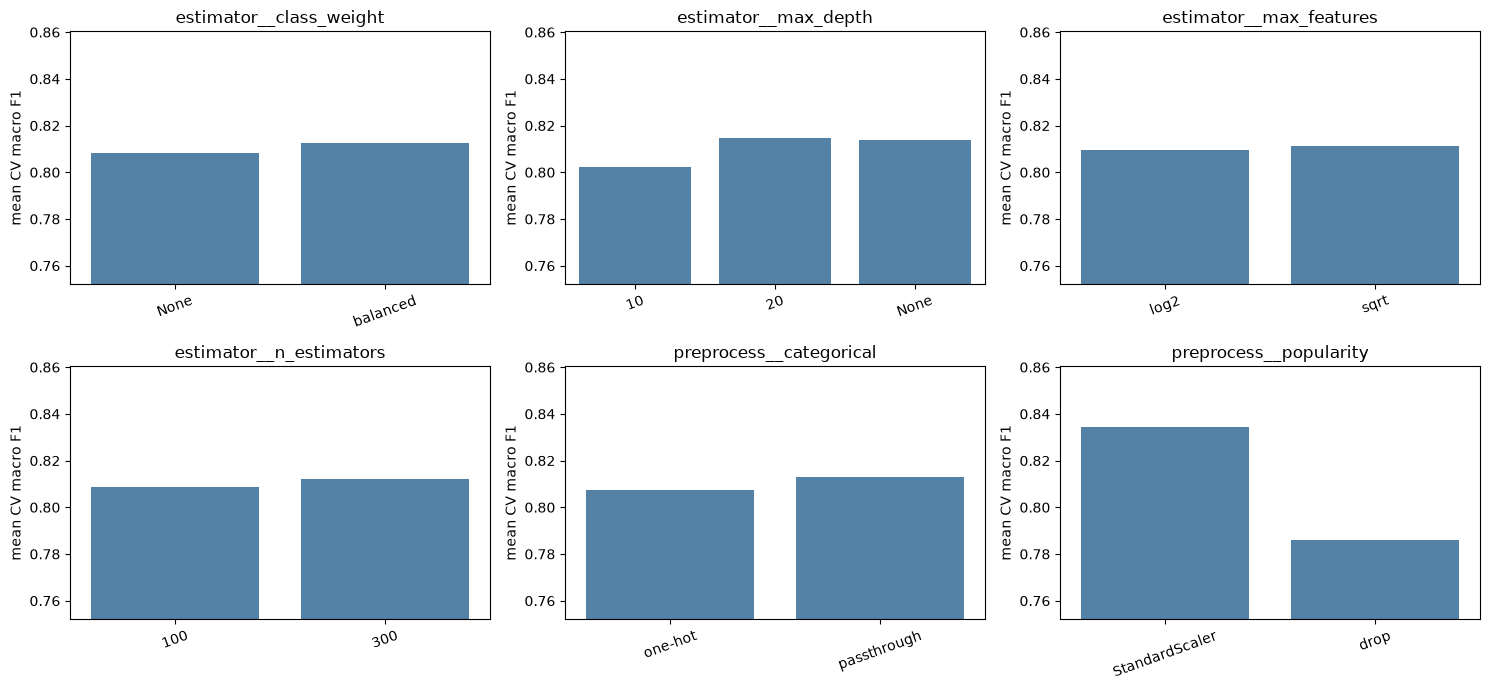

In [58]:
summarize_results(rf_grid)
show_score('Random Forest', rf_grid)
plot_search(rf_grid)

### Interpretation

The best Random Forest reaches a macro F1 of 0.850 ± 0.006, clearly better than both baselines (0.779 and 0.793).

Deeper trees are better up to a point: 0.837 for depth 10 and 0.850 for depth 20. No limit gives the same score
(0.849), so the range is wide enough. 300 trees are slightly better than 100 (0.850 vs 0.844). 300 is the largest
value I tested, so more trees might give a tiny improvement, but the gain from 100 to 300 is already small, and more
trees make the model slower. `sqrt` and `log2` give exactly the same score. With 15 columns, both settings give
3 features per split (√15 ≈ 3.9 and log2(15) ≈ 3.9, rounded down), so they are actually the same setting here.

This is the first model where `class_weight='balanced'` helps (0.850 vs 0.843). When the smaller genres, like jazz
and country, get more weight, the forest finds more of their songs.

`popularity` has the biggest effect again: 0.850 with it and 0.793 without it.

## Ensemble : Gradient Boosting

Gradient Boosting also combines many decision trees, but in a different way than a Random Forest. 
A Random Forest builds its trees independently and lets them vote. Gradient Boosting builds the 
trees one after another, and every new tree focuses on the mistakes the previous trees made.

I use `HistGradientBoostingClassifier`, which is a faster version of Gradient Boosting in scikit-learn. 
The regular version builds one tree per genre at every step, which is slow with six genres.

In [59]:
gb_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', HistGradientBoostingClassifier(random_state=random_state))
])

gb_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__learning_rate': [0.05, 0.1, 0.2],
    'estimator__max_iter': [100, 300],
    'estimator__max_depth': [3, 6, None],
    'estimator__class_weight': [None, 'balanced']
}

gb_grid = GridSearchCV(gb_pipe, gb_params, cv=cv, scoring='f1_macro', n_jobs=-1)
gb_grid.fit(train_features, train_targets)

print(f"Best settings: {gb_grid.best_params_}")
print(f"Best cross-validation F1: {gb_grid.best_score_:.3f}")

Best settings: {'estimator__class_weight': 'balanced', 'estimator__learning_rate': 0.1, 'estimator__max_depth': 6, 'estimator__max_iter': 300, 'preprocess__categorical': OneHotEncoder(handle_unknown='ignore'), 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.868



estimator__class_weight:
None        0.868
balanced    0.868

estimator__learning_rate:
0.05    0.868
0.1     0.868
0.2     0.867

estimator__max_depth:
3       0.859
6       0.868
None    0.868

estimator__max_iter:
100    0.867
300    0.868

preprocess__categorical:
one-hot        0.868
passthrough    0.866

preprocess__popularity:
StandardScaler    0.868
drop              0.796

Gradient Boosting: 0.868 ± 0.006


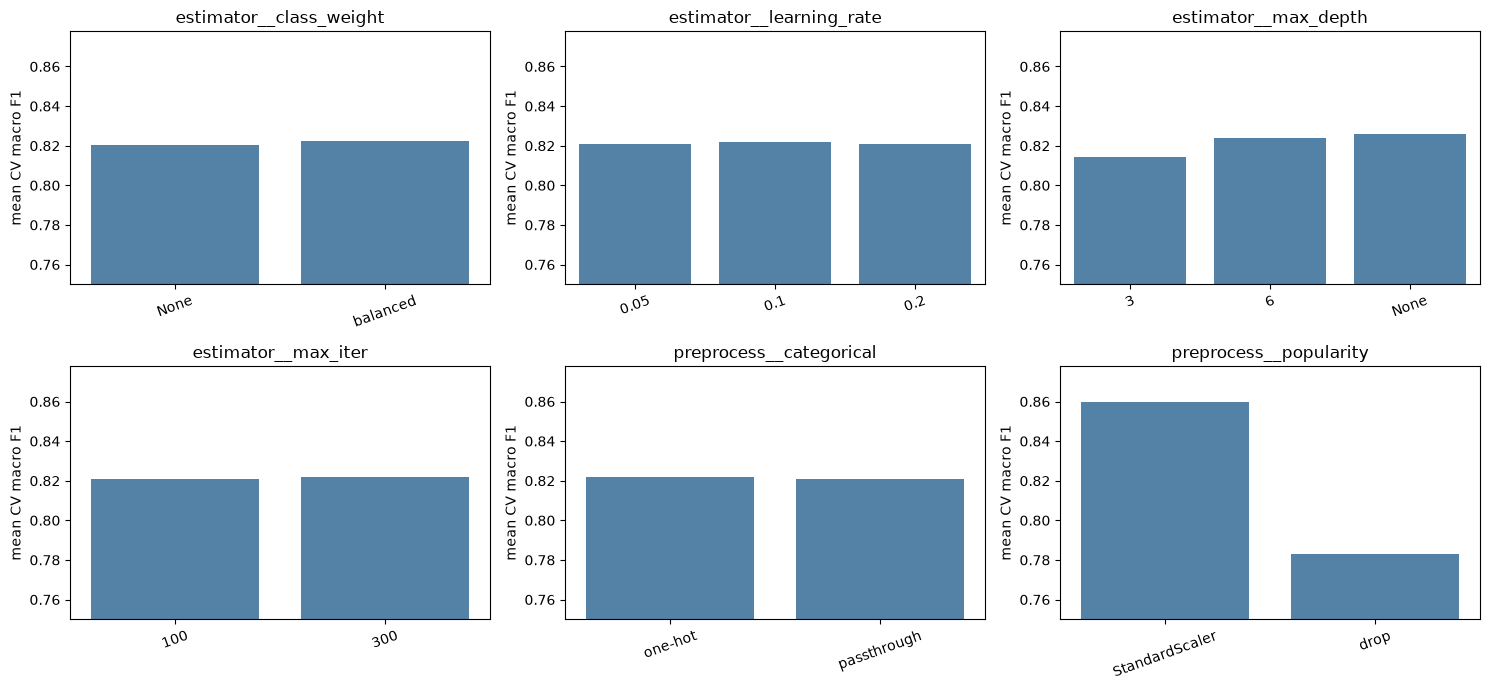

In [60]:
summarize_results(gb_grid)
show_score('Gradient Boosting', gb_grid)
plot_search(gb_grid)

In [61]:
# The 5 fold scores behind the average of the best settings
fold_columns = [f'split{i}_test_score' for i in range(5)]
print(pd.DataFrame(gb_grid.cv_results_).loc[gb_grid.best_index_, fold_columns].astype(float).round(3).to_string())

split0_test_score    0.873
split1_test_score    0.868
split2_test_score    0.861
split3_test_score    0.860
split4_test_score    0.876


### Interpretation

The best Gradient Boosting reaches a macro F1 of 0.868 ± 0.006 in cross-validation, the best of the single models.
It is 0.018 better than the Random Forest (0.850 ± 0.006). That gap is three times as big as the spread between the
folds, so here I think Gradient Boosting really is better, and not just lucky. The five fold scores are between
0.860 and 0.876, so the model is stable.

All three learning rates reach about the same best score (0.867 to 0.868). A low learning rate can catch up if it
gets enough trees, so in the best case it doesn't matter much which one I choose. 100 and 300 trees give almost the
same score (0.867 and 0.868), so the score has levelled out and I don't need to test more. Depth 3 is slightly
worse (0.859) than depth 6, and no depth limit gives the same as depth 6. This is probably because each tree is
already limited to 31 leaves by default.

`class_weight` makes no difference here (0.868 for both). One-hot encoding of `key` and `time_signature` is
slightly better than keeping them as numbers (0.868 vs 0.866), but the difference is very small.

`popularity` has the biggest effect again: 0.868 with it and 0.796 without it.

## Ensemble : Extra Trees

Extra Trees is very similar to a Random Forest: many decision trees that vote together. The difference 
is that a Random Forest searches for the best split value, while Extra Trees picks the split values at 
random. This makes each tree a bit weaker, but the trees are more different from each other, and the 
model trains faster.

In [62]:
et_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', ExtraTreesClassifier(random_state=random_state))
])

extrees_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__n_estimators': [100, 300],          # how many trees
    'estimator__max_depth': [10, 20, 30, None],
    'estimator__max_features': ['sqrt', 0.5, 1.0],  # share of the features each split can choose from
    'estimator__class_weight': [None, 'balanced']
}

extrees_grid = GridSearchCV(et_pipe, extrees_params, cv=cv, scoring='f1_macro', n_jobs=-1)
extrees_grid.fit(train_features, train_targets)

print(f"Best settings: {extrees_grid.best_params_}")
print(f"Best cross-validation F1: {extrees_grid.best_score_:.3f}")

Best settings: {'estimator__class_weight': None, 'estimator__max_depth': 20, 'estimator__max_features': 1.0, 'estimator__n_estimators': 300, 'preprocess__categorical': OneHotEncoder(handle_unknown='ignore'), 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.851



estimator__class_weight:
None        0.851
balanced    0.849

estimator__max_depth:
10      0.836
20      0.851
30      0.849
None    0.850

estimator__max_features:
0.5     0.850
1.0     0.851
sqrt    0.835

estimator__n_estimators:
100    0.850
300    0.851

preprocess__categorical:
one-hot        0.851
passthrough    0.850

preprocess__popularity:
StandardScaler    0.851
drop              0.783

Extra Trees: 0.851 ± 0.010


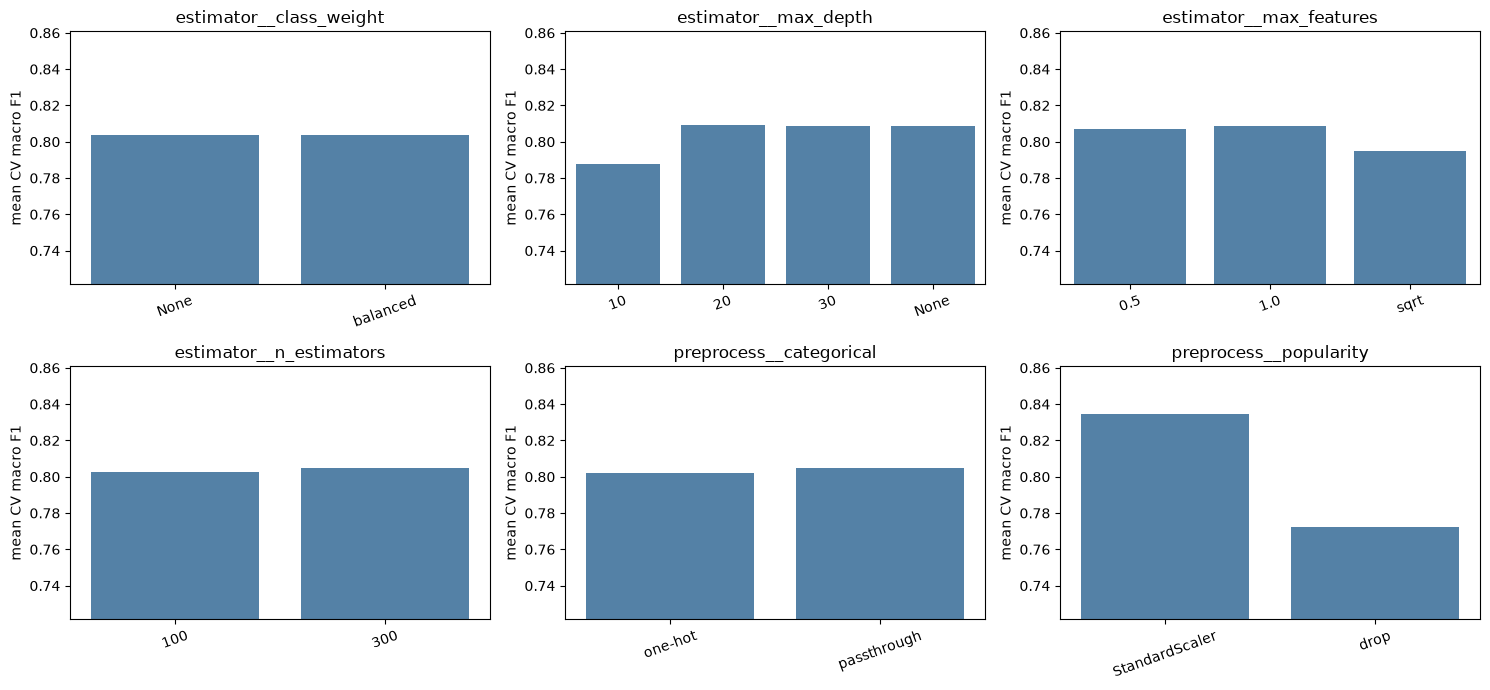

In [63]:
summarize_results(extrees_grid)
show_score('Extra Trees', extrees_grid)
plot_search(extrees_grid)

### Interpretation

The best Extra Trees reaches a macro F1 of 0.851 ± 0.010. This is the same as the Random Forest (0.850 ± 0.006)
and below Gradient Boosting (0.868).

A depth of 10 is too shallow (0.836), but from depth 20 the score levels out (0.849 to 0.851), so a deeper forest
would not help. 100 and 300 trees give almost the same score. For `max_features`, `sqrt` is clearly worse (0.835)
than half of the features (0.850) or all of them (0.851). This is the opposite of the Random Forest. I think this
is because Extra Trees picks its split values at random, so each split needs more features to choose from to find
a good one.

`class_weight` makes almost no difference (0.851 vs 0.849), and neither does the encoding (0.851 vs 0.850).
`popularity` has the biggest effect again: 0.851 with it and 0.783 without it.

# ARTIFICIAL NEURAL NETWORKS

## What is a neural network?

A neural network is a machine-learning model that learns how to make predictions from examples. In this project, it receives the processed numeric features of a song—such as energy, acousticness, duration, and encoded category information—and tries to predict the song’s genre. It does not begin by knowing what “high energy” or “classical music” means. Instead, it looks at many labelled songs and gradually learns which combinations of numeric patterns are associated with each genre.

A neural network is made from layers of small calculations called **neurons**. Each neuron receives input values and gives each input a learned **weight**. A weight represents how that input affects the neuron’s current calculation: a positive weight pushes its score upward, while a negative weight pushes it downward. The neuron also has a **bias**, which acts like a learned starting point or threshold. Both weights and biases begin as small random values and are adjusted during training.

After combining its inputs, a neuron uses an **activation function**. In hidden layers, a common activation function is ReLU, which changes negative values to zero and keeps positive values. Activations are important because they allow the network to learn complex patterns instead of only simple straight-line relationships. Several layers of neurons can therefore learn increasingly useful combinations of the original song features.

At the end of the network, the model produces a score for every possible genre. For a problem where each song has one genre, softmax converts these scores into probabilities that add up to 100%. For example, the model might predict a 70% probability of jazz, 20% classical and 10% country, then choose jazz as its prediction.

During training, the network compares its predicted probabilities with the true genre label. It calculates a **loss**, which is a number representing how wrong the prediction was. A low loss means the model gave high probability to the correct genre; a high loss means it was confidently wrong. Using backpropagation and gradient descent, the model makes small adjustments to its weights and biases to reduce the loss. Repeating this process over many songs and many training rounds allows the neural network to improve its predictions.

I train two neural networks: an `MLPClassifier` from scikit-learn, and a network built with Keras.

## ANN 1: MLPClassifier

`MLPClassifier` is scikit-learn's neural network. I tune the size of the hidden layers, the activation
function, the regularization (`alpha`) and the learning rate, together with the processing alternatives.
With `early_stopping=True` it keeps 10% of its training data aside and stops when the score on that
part stops improving. There are many combinations, so I use `RandomizedSearchCV`, which tests 40
random combinations instead of all of them.

In [64]:
mlp_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', MLPClassifier(max_iter=300,early_stopping=True, random_state=random_state))
])

In [65]:
mlp_params = {
    # Processing alternatives
    'preprocess__numeric__power': ['passthrough', PowerTransformer()],
    'preprocess__numeric__scale': [StandardScaler(), MinMaxScaler()],
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__hidden_layer_sizes': [(64,), (128, 64), (128, 64, 32)],
    'estimator__activation': ['relu', 'tanh'],
    'estimator__alpha': [1e-4, 1e-3, 1e-2],
    'estimator__learning_rate_init': [1e-3, 3e-3, 1e-2, 3e-2]
}

In [66]:
mlp_search = RandomizedSearchCV(mlp_pipe, mlp_params, n_iter=40, cv=cv, scoring='f1_macro',
                                random_state=random_state, n_jobs=-1)
mlp_search.fit(train_features, train_targets)

print(f"Best settings: {mlp_search.best_params_}")
print(f"Best cross-validation F1: {mlp_search.best_score_:.3f}")

Best settings: {'preprocess__popularity': StandardScaler(), 'preprocess__numeric__scale': StandardScaler(), 'preprocess__numeric__power': 'passthrough', 'preprocess__categorical': 'passthrough', 'estimator__learning_rate_init': 0.003, 'estimator__hidden_layer_sizes': (128, 64, 32), 'estimator__alpha': 0.001, 'estimator__activation': 'tanh'}
Best cross-validation F1: 0.814



preprocess__popularity:
StandardScaler    0.814
drop              0.758

preprocess__numeric__scale:
MinMaxScaler      0.812
StandardScaler    0.814

preprocess__numeric__power:
PowerTransformer    0.812
passthrough         0.814

preprocess__categorical:
one-hot        0.807
passthrough    0.814

estimator__learning_rate_init:
0.001    0.797
0.003    0.814
0.01     0.812
0.03     0.803

estimator__hidden_layer_sizes:
(128, 64)        0.799
(128, 64, 32)    0.814
(64,)            0.803

estimator__alpha:
0.0001    0.807
0.001     0.814
0.01      0.797

estimator__activation:
relu    0.797
tanh    0.814

MLP: 0.814 ± 0.012


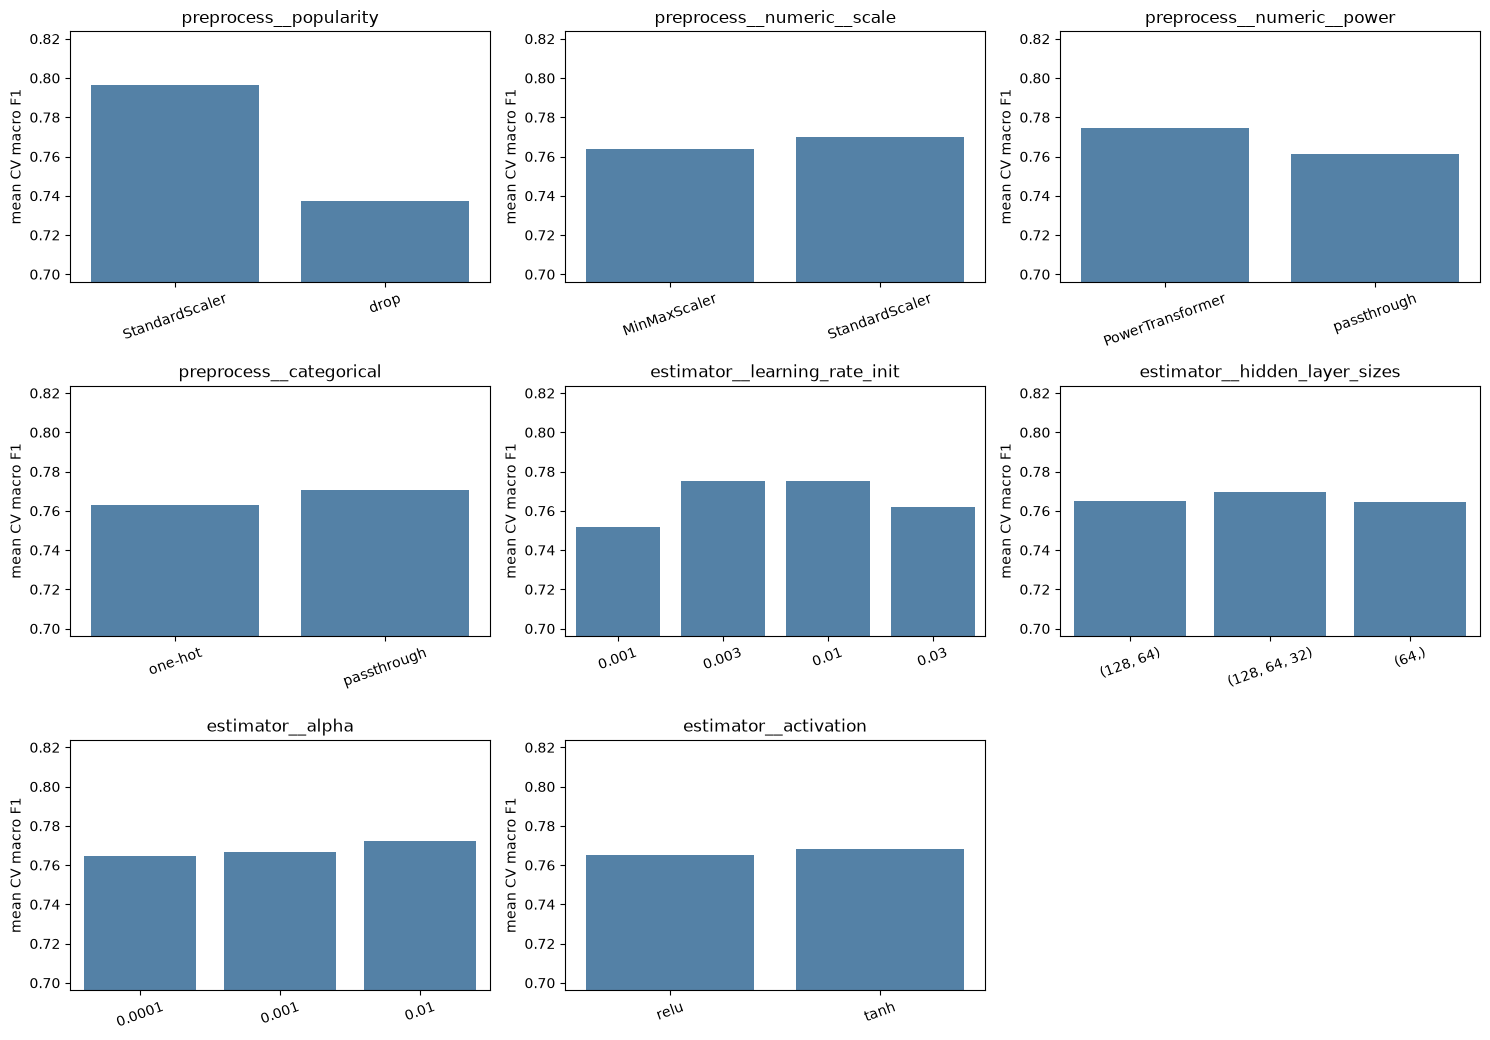

In [67]:
summarize_results(mlp_search)
show_score('MLP', mlp_search)
plot_search(mlp_search)

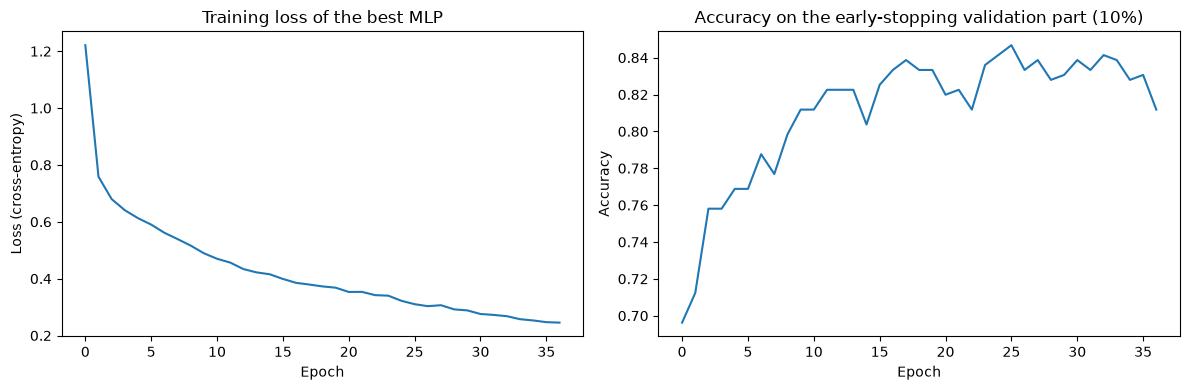

In [68]:
best_mlp = mlp_search.best_estimator_.named_steps['estimator']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_mlp.loss_curve_)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (cross-entropy)')
axes[0].set_title('Training loss of the best MLP')

axes[1].plot(best_mlp.validation_scores_)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy on the early-stopping validation part (10%)')
plt.tight_layout()
plt.show()

### Interpretation

The best MLP reaches a macro F1 of 0.814 ± 0.012. That is better than the two baselines (0.779 and 0.793), but
clearly worse than the three tree ensembles (0.850 to 0.868).

The best network has three hidden layers (128, 64 and 32 neurons), the `tanh` activation, `alpha=0.001` and a
learning rate of 0.003. The learning rate and `alpha` are both in the middle of the ranges I tested: a learning
rate of 0.001 is too slow (0.797) and 0.03 is too big (0.803), and the strongest regularization (`alpha=0.01`) is
too strong (0.797). `tanh` is better than ReLU (0.814 vs 0.797). The biggest network is the best, but the
difference to the smaller ones is small.

For the processing, `StandardScaler` is slightly better than `MinMaxScaler` (0.814 vs 0.812), and the
`PowerTransformer` doesn't help (0.812 vs 0.814). Keeping `key` and `time_signature` as numbers is better than
one-hot (0.814 vs 0.807). `popularity` has the biggest effect again: 0.814 with it and 0.758 without it.

The plots show the training of the best MLP. The training loss keeps falling the whole time. The accuracy on the
early-stopping validation part goes up quickly at first, but after about 15 to 25 epochs it stops improving and
goes up and down between 0.81 and 0.85. This is the start of overfitting: the network keeps learning the training
data, but it doesn't get better on new data. Early stopping ends the training when the validation score hasn't
improved for 10 epochs, which happened after about 37 epochs.

## ANN 2: Keras network

Keras is a library for building neural networks layer by layer, and it is the tool we used in the
course. I build the network myself with `keras.Sequential`:

- an **input layer** with one input per processed feature
- one to three **hidden layers** (`Dense`) with ReLU activation
- a **dropout** layer after each hidden layer, which switches off a random share of the neurons
  during training, so the network can't rely too much on single neurons (this reduces overfitting)
- an **output layer** with one neuron per genre and **softmax**, which gives one probability per genre

The loss is `sparse_categorical_crossentropy`, which is the cross-entropy loss for labels stored as
numbers (0 to 5). The optimizer is Adam. `EarlyStopping` stops the training when the validation loss
hasn't improved for 10 epochs, and goes back to the best weights.

Keras runs on top of a "backend" that does the actual calculations. I use PyTorch (set in the first
code cell). To use the Keras network in a scikit-learn `Pipeline` and `RandomizedSearchCV`, I wrap it
in `KerasClassifier` from the `scikeras` library.

Note: neural network training uses random numbers, so the Keras results can differ slightly between runs.

In [69]:
# Check which versions and which backend are used
print(f"Keras {keras.__version__}, backend: {keras.backend.backend()}, scikeras {scikeras.__version__}")

Keras 3.15.1, backend: torch, scikeras 0.13.0


In [70]:
def build_model(meta, hidden_units=(64, 32), dropout=0.0):
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(meta["n_features_in_"],)))        # one input per column
    for units in hidden_units:
        model.add(keras.layers.Dense(units, activation='relu'))           # a hidden layer
        model.add(keras.layers.Dropout(dropout))                          # switch off a share of neurons
    model.add(keras.layers.Dense(meta["n_classes_"], activation='softmax'))   # output: one probability per genre
    return model

In [71]:
keras_clf = KerasClassifier(
    model=build_model,
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    optimizer__learning_rate=1e-3,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
    verbose=0,
    random_state=random_state
)

In [72]:
keras_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', keras_clf)
])

In [73]:
keras_params = {
    # Processing alternatives
    'preprocess__numeric__power': ['passthrough', PowerTransformer()],
    'preprocess__popularity': ['drop', StandardScaler()],
    # Model parameters
    'estimator__model__hidden_units': [(64,), (128, 64), (128, 64, 32)],
    'estimator__model__dropout': [0.0, 0.2, 0.4],
    'estimator__optimizer__learning_rate': [3e-4, 1e-3, 3e-3, 1e-2],
    'estimator__batch_size': [32, 128]
}

In [74]:
# n_jobs=1: the Keras models are trained one at a time, since PyTorch already uses several CPU cores
keras_search = RandomizedSearchCV(keras_pipe, keras_params, n_iter=15, cv=cv, scoring='f1_macro',
                                  random_state=random_state, n_jobs=1)
keras_search.fit(train_features, train_targets)

print(f"Best settings: {keras_search.best_params_}")
print(f"Best cross-validation F1: {keras_search.best_score_:.3f}")

Best settings: {'preprocess__popularity': StandardScaler(), 'preprocess__numeric__power': 'passthrough', 'estimator__optimizer__learning_rate': 0.0003, 'estimator__model__hidden_units': (128, 64, 32), 'estimator__model__dropout': 0.0, 'estimator__batch_size': 32}
Best cross-validation F1: 0.800



preprocess__popularity:
StandardScaler    0.800
drop              0.764

preprocess__numeric__power:
PowerTransformer    0.793
passthrough         0.800

estimator__optimizer__learning_rate:
0.0003    0.800
0.001     0.793
0.003     0.800
0.01      0.798

estimator__model__hidden_units:
(128, 64)        0.798
(128, 64, 32)    0.800
(64,)            0.800

estimator__model__dropout:
0.0    0.800
0.2    0.798
0.4    0.793

estimator__batch_size:
32     0.800
128    0.793

Keras network: 0.800 ± 0.012


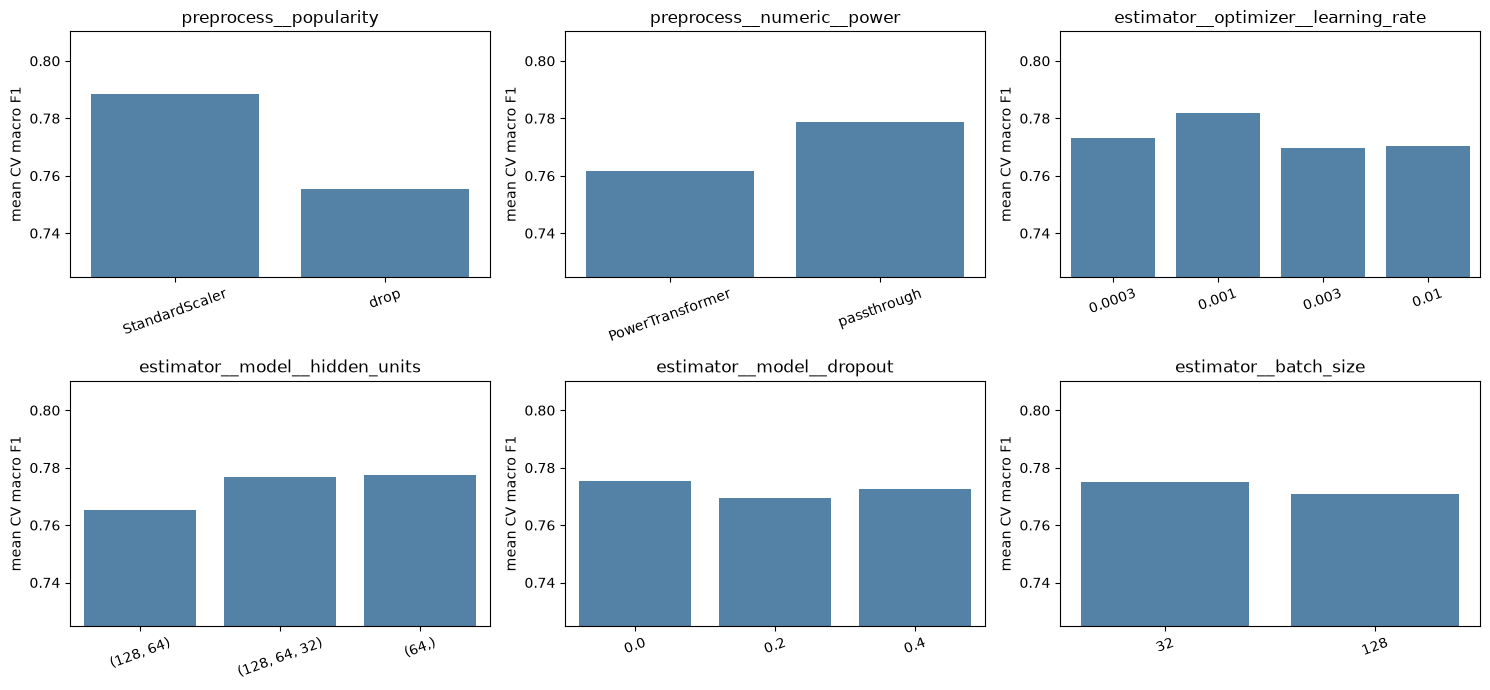

In [75]:
summarize_results(keras_search)
show_score('Keras network', keras_search)
plot_search(keras_search)

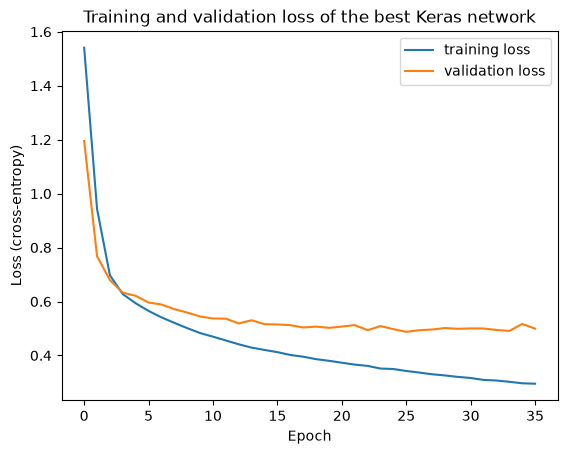

In [76]:
history = keras_search.best_estimator_.named_steps['estimator'].history_

plt.plot(history['loss'], label='training loss')
plt.plot(history['val_loss'], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (cross-entropy)')
plt.title('Training and validation loss of the best Keras network')
plt.legend()
plt.show()

### Interpretation

The best Keras network reaches a macro F1 of 0.800 ± 0.012 in cross-validation, a bit lower than the MLP (0.814).

The best settings are three hidden layers (128, 64 and 32 neurons), no dropout, a learning rate of 0.0003 and a
batch size of 32. But most settings give almost the same score: the three network sizes are between 0.798 and
0.800, and the four learning rates between 0.793 and 0.800. These differences are smaller than the spread between
the folds (0.012), so I can't say that they matter. 0.0003 is the lowest learning rate I tested, but 0.003 gives
the same score, so a lower value probably wouldn't help. Dropout 0.4 is slightly worse (0.793), and small batches
are slightly better than big batches (0.800 vs 0.793). The `PowerTransformer` doesn't help (0.793 vs 0.800).
`popularity` matters the most again: 0.800 with it and 0.764 without it.

The loss curves show the training of the best network on the whole training set. Both losses fall quickly in the
first 5 epochs. After that, the training loss keeps falling, while the validation loss flattens out at about 0.50
from around epoch 15. This is the start of overfitting: the network keeps getting better on the training data,
but not on new data. Early stopping ended the training at epoch 35 and went back to the weights from the best epoch.

# EXTRA MODEL: STACKING ENSEMBLE

The assignment is about ensembles, so as an extra I combine the best models in a **stacking ensemble**.
The base models (Random Forest, Gradient Boosting, KNN and the MLP) each make a prediction, and a
final model (logistic regression) learns how to combine their predicted probabilities. The idea is
that different kinds of models make different mistakes, so together they can be better than each
one alone.

To train the final model fairly, `StackingClassifier` uses cross-validation inside the training data:
the base models predict songs they were not trained on, and these predictions become the training
data for the final model. I tune how many folds it uses for this (`cv`), and how strongly the final
logistic regression is regularized (`C`). The base models keep the settings they got in their own tuning.

In [77]:
# The tuned base models from above. Each one keeps its own preprocessing,
# since every model needs different processing (KNN needs scaling, the trees don't).
base_models = [
    ('rf', rf_grid.best_estimator_),
    ('gb', gb_grid.best_estimator_),
    ('knn', knn_grid.best_estimator_),
    ('mlp', mlp_search.best_estimator_),
]

stack = StackingClassifier(estimators=base_models, final_estimator=LogisticRegression(max_iter=1000))

stack_params = {
    'final_estimator__C': [0.01, 0.1, 1, 10],   # smaller C = stronger regularization of the final model
    'cv': [3, 5],                               # folds used to make the training data for the final model
}

stack_grid = GridSearchCV(stack, stack_params, cv=cv, scoring='f1_macro', n_jobs=-1)
stack_grid.fit(train_features, train_targets)

print(f"Best settings: {stack_grid.best_params_}")
print(f"Best cross-validation F1: {stack_grid.best_score_:.3f}")

Best settings: {'cv': 3, 'final_estimator__C': 1}
Best cross-validation F1: 0.869



cv:
3    0.869
5    0.867

final_estimator__C:
0.01    0.867
0.1     0.868
1.0     0.869
10.0    0.865

Stacking: 0.869 ± 0.010


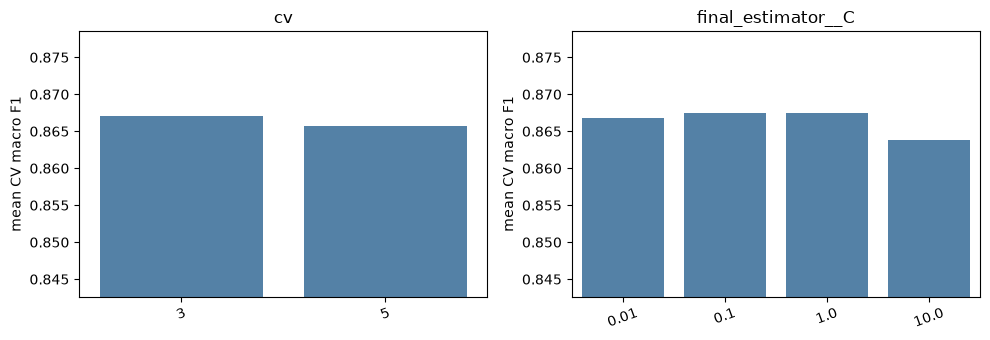

In [78]:
summarize_results(stack_grid)
show_score('Stacking', stack_grid)
plot_search(stack_grid, ncols=2)

### Interpretation

The stacking ensemble reaches a macro F1 of 0.869 ± 0.010. That is the highest score of all the models, but only
0.001 better than Gradient Boosting alone (0.868 ± 0.006). The difference is much smaller than the spread between
the folds, so combining the four models doesn't really help here.

I think this is because the base models make many of the same mistakes. The biggest problem for all of them is
telling country and jazz apart, and when all the base models are unsure about the same songs, the final model has
nothing better to choose from. Gradient Boosting is also much stronger than KNN and the MLP, so the other base
models probably add little that Gradient Boosting doesn't already know.

The tuning shows the same thing: all the settings give almost the same score (0.865 to 0.869). Using 3 folds to
build the training data for the final model is as good as using 5, and `C=1` is in the middle of the range, so
very strong (0.01) or very weak (10) regularization is a bit worse.

# EVALUATION

## Cross-validation comparison

First I compare all the tuned models on their cross-validation scores. The final model is chosen
here, before the test set is used. I also show the score on the training data, to see how much each
model overfits, and how long one training run takes.

In [79]:
# All the tuned models in one place. Each search has already refitted its best settings on the whole training set.
searches = {
    'Decision Tree': dt_grid,
    'KNN': knn_grid,
    'Random Forest': rf_grid,
    'Extra Trees': extrees_grid,
    'Gradient Boosting': gb_grid,
    'MLP': mlp_search,
    'Keras network': keras_search,
    'Stacking': stack_grid,
}
best_models = {name: search.best_estimator_ for name, search in searches.items()}

# Cross-validation score, training score and training time of the best settings of every model
rows = {}
for name, search in searches.items():
    best = pd.DataFrame(search.cv_results_).loc[search.best_index_]
    rows[name] = {
        'CV F1': best['mean_test_score'],
        'CV std': best['std_test_score'],
        'Train F1': f1_score(train_targets, search.predict(train_features), average='macro'),
        'Fit time (s)': best['mean_fit_time'],
    }
cv_table = pd.DataFrame(rows).T
cv_table.loc['Random guess'] = [dummy_scores.mean(), dummy_scores.std(), np.nan, np.nan]
cv_table['Train - CV'] = cv_table['Train F1'] - cv_table['CV F1']     # a big gap means overfitting
cv_table = cv_table.astype(float).sort_values('CV F1', ascending=False).round(3)
cv_table

,CV F1,CV std,Train F1,Fit time (s),Train - CV
Stacking,0.869,0.010,1.000,16.606,0.131
Gradient Boosting,0.868,0.006,1.000,3.522,0.132
Extra Trees,0.851,0.010,1.000,2.052,0.149
Random Forest,0.850,0.006,1.000,1.291,0.150
MLP,0.814,0.012,0.877,0.550,0.063
Keras network,0.800,0.012,0.858,13.959,0.058
KNN,0.793,0.011,1.000,0.126,0.207
Decision Tree,0.779,0.007,0.910,0.028,0.131
Random guess,0.162,0.009,NaN,NaN,NaN


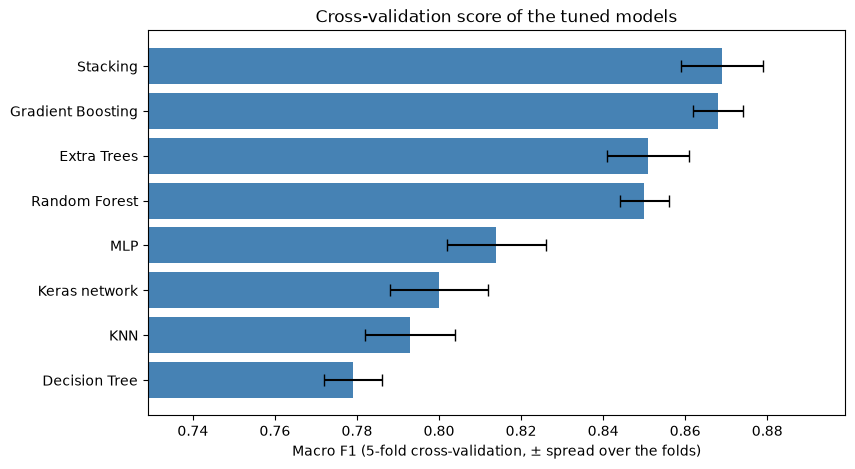

Best CV score: Stacking (0.869 ± 0.010)
Models within one standard deviation of it: ['Stacking', 'Gradient Boosting']
Final model (the fastest of these): Gradient Boosting


In [80]:
plot_table = cv_table.drop('Random guess')

plt.figure(figsize=(9, 5))
plt.barh(plot_table.index, plot_table['CV F1'], xerr=plot_table['CV std'], color='steelblue', capsize=4)
plt.xlim(plot_table['CV F1'].min() - 0.05, min(1, plot_table['CV F1'].max() + 0.03))
plt.gca().invert_yaxis()             # best model at the top
plt.xlabel('Macro F1 (5-fold cross-validation, ± spread over the folds)')
plt.title('Cross-validation score of the tuned models')
plt.show()

# The final model is chosen on the cross-validation results only, before looking at the test set.
# Rule: start from the best CV score. If other models are within one standard deviation of it, the
# difference could just be noise, so I choose the fastest of those models, since it is the simplest.
best_row = plot_table['CV F1'].idxmax()
candidates = plot_table[plot_table['CV F1'] >= plot_table.loc[best_row, 'CV F1'] - plot_table.loc[best_row, 'CV std']]
best_name = candidates['Fit time (s)'].idxmin()

print(f"Best CV score: {best_row} ({plot_table.loc[best_row, 'CV F1']:.3f} ± {plot_table.loc[best_row, 'CV std']:.3f})")
print(f"Models within one standard deviation of it: {list(candidates.index)}")
print(f"Final model (the fastest of these): {best_name}")

### Interpretation

The three tree ensembles and the stacking model are clearly the best (0.850 to 0.869), the two neural networks are
in the middle (0.800 and 0.814), and the two baselines are the weakest (0.779 and 0.793). All the models are far
above random guessing (0.162).

The `Train - CV` column shows how much each model overfits. The tree ensembles and KNN score 1.000 on the training
data. For the ensembles this is normal, since deep trees can remember every training song, and it doesn't hurt them
because the vote of many different trees still works well on new songs. For KNN, the perfect training score comes
from `weights='distance'`: a training song is its own nearest neighbour with a distance of 0, so it always gets its
own genre. The two neural networks overfit the least (gaps of about 0.06), because early stopping stops them before
they memorize the training data.

The fit time shows what each model costs. The stacking model takes about 17 seconds to train, almost five times as
long as Gradient Boosting (3.5 seconds), because it has to train all four base models several times.

**Choosing the final model:** Stacking has the best cross-validation score (0.869 ± 0.010), but Gradient Boosting
(0.868 ± 0.006) is within one standard deviation of it. A difference of 0.001 could just be noise, so I use the rule
in the code above and choose the faster of the two: **Gradient Boosting**. It is simpler, about five times faster,
and the stacking model is partly built from it anyway. I made this choice before looking at the test set.

## Test set results

Now, for the first and only time, I test all the tuned models on the test set, which none of the
models have seen. After this, I don't change any model because of these results.

In [81]:
test_models = {'Random guess': dummy, **best_models}

test_predictions = {name: model.predict(test_features) for name, model in test_models.items()}
test_probabilities = {name: model.predict_proba(test_features) for name, model in test_models.items()}

In [82]:
test_results = {}
for name, pred in test_predictions.items():
    test_results[name] = {
        'Accuracy': accuracy_score(test_targets, pred),
        'Precision': precision_score(test_targets, pred, average='macro'),
        'Recall': recall_score(test_targets, pred, average='macro'),
        'F1': f1_score(test_targets, pred, average='macro'),
        'ROC-AUC': roc_auc_score(test_targets, test_probabilities[name], multi_class='ovr', average='macro'),
    }

test_results_df = pd.DataFrame(test_results).T
test_results_df['CV F1'] = cv_table['CV F1']                       # to compare with the test F1
test_results_df['Test - CV'] = test_results_df['F1'] - test_results_df['CV F1']
test_results_df = test_results_df.sort_values('F1', ascending=False).round(3)
test_results_df

,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1,Test - CV
Gradient Boosting,0.877,0.860,0.858,0.859,0.982,0.868,-0.009
Stacking,0.872,0.855,0.850,0.852,0.981,0.869,-0.017
Extra Trees,0.858,0.839,0.839,0.838,0.975,0.851,-0.013
Random Forest,0.856,0.837,0.837,0.836,0.977,0.850,-0.014
Keras network,0.852,0.831,0.831,0.831,0.972,0.800,0.031
MLP,0.835,0.814,0.812,0.813,0.973,0.814,-0.001
KNN,0.810,0.789,0.783,0.784,0.962,0.793,-0.009
Decision Tree,0.792,0.774,0.774,0.773,0.908,0.779,-0.006
Random guess,0.159,0.160,0.162,0.158,0.500,0.162,-0.004


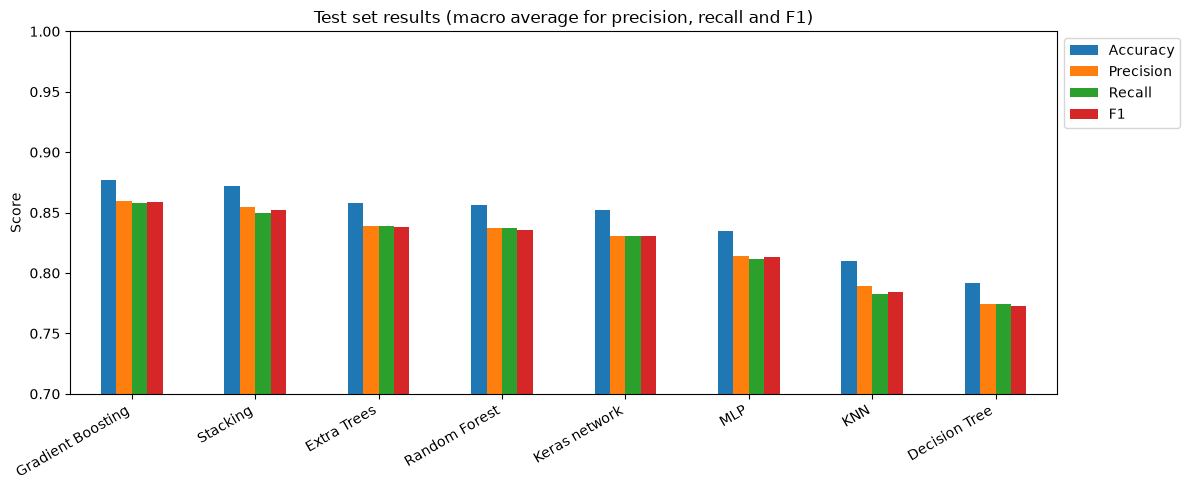

In [83]:
bars = test_results_df.drop('Random guess')[['Accuracy', 'Precision', 'Recall', 'F1']]

bars.plot(kind='bar', figsize=(12, 5))
plt.title('Test set results (macro average for precision, recall and F1)')
plt.ylabel('Score')
plt.ylim(np.floor((bars.min().min() - 0.03) * 20) / 20, 1.0)    # zoomed in so the differences are visible
plt.xticks(rotation=30, ha='right')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))     # outside the plot, so it hides no bars
plt.tight_layout()
plt.show()

### Interpretation

On the test set, Gradient Boosting is the best model with an accuracy of 0.877 and a macro F1 of 0.859, followed
by Stacking (0.852), Extra Trees (0.838) and Random Forest (0.836). The order is almost the same as in the
cross-validation, so my choice of the final model holds up on new songs. The Decision Tree is the weakest
(F1 0.773), but still far above random guessing (0.158).

The `Test - CV` column shows that most models score a little lower on the test set than in the cross-validation,
by 0.001 to 0.017. This is normal: the tuning picked the settings that happened to work best on the folds, so the
CV score is a bit optimistic. The differences are small, so the tuning didn't overfit to the folds. The Keras
network is the exception: it does 0.031 better on the test set than in the cross-validation. I think this is
mostly luck, since neural networks vary from run to run, and the final network is trained on all the training data
instead of 80% of it.

Accuracy is about 0.02 higher than the macro F1 for every model. This is because of the imbalance: accuracy counts
every song, so the big genres like heavy-metal and techno, which are easy, count more. The macro F1 gives the small
and difficult genres, jazz and country, the same weight, so it is lower. Precision and recall are almost equal for
every model, so the models don't systematically predict too many or too few songs.

All the ROC-AUC values are high (0.908 to 0.982), which means the predicted probabilities rank the songs well, even
when the final prediction is wrong.

## Confusion Matrices

Confusion matrices are used to look closer at how the model classifies the different genres. Each row
is the true genre and each column is the predicted genre. The diagonal shows the songs the model got
right, and every number outside the diagonal is a mistake. With six genres there is no single
"positive" class, so instead of TP, TN, FP and FN, the matrix shows exactly which genre each song was
mistaken for.

This gives more information than accuracy alone, since we can see which genres the model mixes up.
I show one confusion matrix for every model on the test set, the same way as in my first project.

In [84]:
# A function for plotting a confusion matrix for a model on test data.
# It also prints how many songs were correct per genre, and the biggest mistakes.
def show_confusion(name):
    genre_names = label_encoder.classes_
    matrix = confusion_matrix(test_targets, test_predictions[name])

    ConfusionMatrixDisplay(matrix, display_labels=genre_names).plot(xticks_rotation=45, colorbar=False)
    plt.title(f'{name} (test set)')
    plt.show()

    correct = np.diag(matrix)
    print(f"Correct: {correct.sum()} of {matrix.sum()} songs ({correct.sum() / matrix.sum():.1%})")
    print("Correct per genre: " + ", ".join(f"{genre} {right}/{total}"
                                             for genre, right, total in zip(genre_names, correct, matrix.sum(axis=1))))
    mistakes = [(matrix[i, j], genre_names[i], genre_names[j])
                for i in range(len(genre_names)) for j in range(len(genre_names)) if i != j and matrix[i, j] > 0]
    print("Biggest mistakes (true -> predicted): " + ", ".join(f"{true} -> {pred}: {count}"
                                                               for count, true, pred in sorted(mistakes, reverse=True)[:5]))

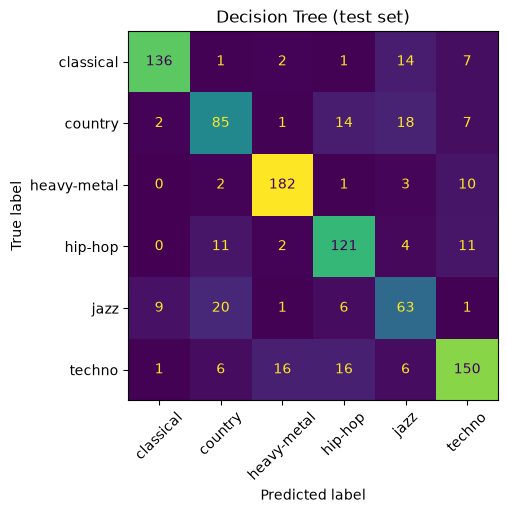

Correct: 737 of 930 songs (79.2%)
Correct per genre: classical 136/161, country 85/127, heavy-metal 182/198, hip-hop 121/149, jazz 63/100, techno 150/195
Biggest mistakes (true -> predicted): jazz -> country: 20, country -> jazz: 18, techno -> hip-hop: 16, techno -> heavy-metal: 16, country -> hip-hop: 14


In [85]:
show_confusion('Decision Tree')

#### Decision Tree confusion matrix:

The confusion matrix shows that the model correctly predicted 737 of the 930 songs (79.2%). Heavy-metal is the
easiest genre: 182 of 198 songs are correct. Classical (136 of 161) and techno (150 of 195) also do quite well.
Jazz is the hardest genre, only 63 of 100 jazz songs are correct, followed by country with 85 of 127.

The biggest mistakes are between jazz and country: 20 jazz songs were predicted as country, and 18 country songs
as jazz. Techno is mixed up with both heavy-metal and hip-hop (16 songs each), 14 classical songs were predicted
as jazz, and 14 country songs as hip-hop.

So the Decision Tree finds the very different genres well, but has problems with the genres that sound similar.
A single tree makes hard yes/no splits, so songs that are close to a split value easily end up in the wrong genre.

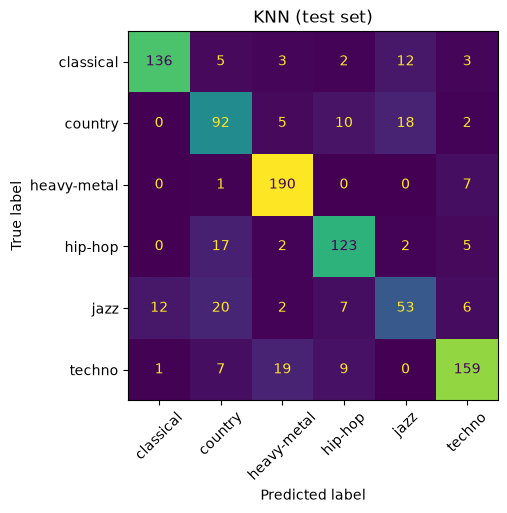

Correct: 753 of 930 songs (81.0%)
Correct per genre: classical 136/161, country 92/127, heavy-metal 190/198, hip-hop 123/149, jazz 53/100, techno 159/195
Biggest mistakes (true -> predicted): jazz -> country: 20, techno -> heavy-metal: 19, country -> jazz: 18, hip-hop -> country: 17, jazz -> classical: 12


In [86]:
show_confusion('KNN')

#### KNN confusion matrix:

The confusion matrix shows that the model correctly predicted 753 of the 930 songs (81.0%), a bit more than the
Decision Tree. KNN gets more of the heavy-metal (190 of 198), techno (159 of 195) and country songs (92 of 127)
right.

But KNN is even worse on jazz: only 53 of 100 jazz songs are correct. Jazz is the smallest genre, so when KNN looks
at the 11 nearest songs, there are often more country or classical songs nearby than jazz songs, and the vote goes
to the bigger genre. This shows up in the biggest mistakes: 20 jazz songs were predicted as country and 12 as
classical. Techno is also mixed up with heavy-metal (19 songs), which are the two most energetic genres, and 17
hip-hop songs were predicted as country.

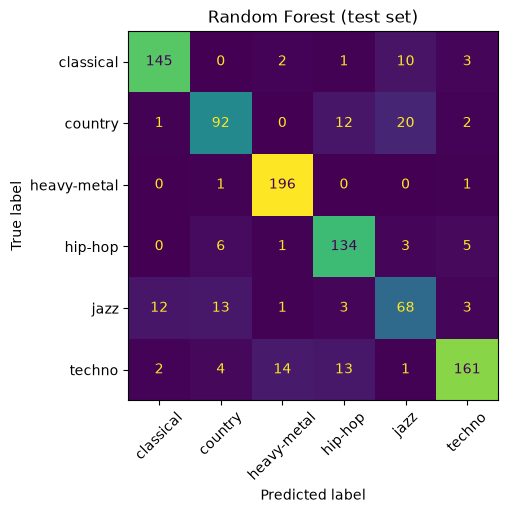

Correct: 796 of 930 songs (85.6%)
Correct per genre: classical 145/161, country 92/127, heavy-metal 196/198, hip-hop 134/149, jazz 68/100, techno 161/195
Biggest mistakes (true -> predicted): country -> jazz: 20, techno -> heavy-metal: 14, techno -> hip-hop: 13, jazz -> country: 13, jazz -> classical: 12


In [87]:
show_confusion('Random Forest')

#### Random Forest confusion matrix:

The confusion matrix shows that the model correctly predicted 796 of the 930 songs (85.6%), which is clearly better
than the two baselines. Heavy-metal is almost perfect, with 196 of 198 songs correct. Jazz improves from 53 correct
songs (KNN) to 68, which fits with `class_weight='balanced'` giving the smaller genres more weight.

The biggest mistake is now country predicted as jazz (20 songs), so the balanced weights also make the model guess
jazz a bit more often. Techno is still mixed up with heavy-metal (14) and hip-hop (13), and 12 jazz songs were
predicted as classical.

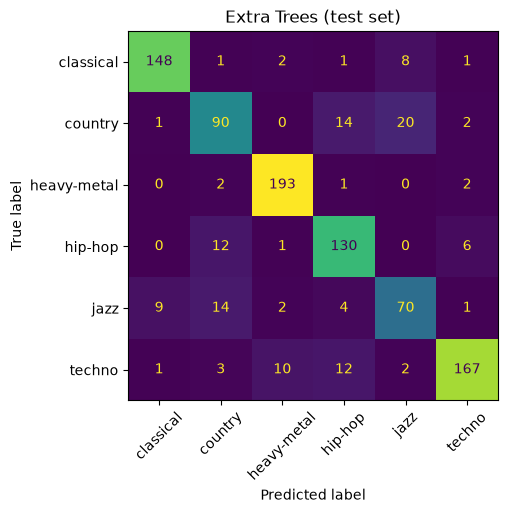

Correct: 798 of 930 songs (85.8%)
Correct per genre: classical 148/161, country 90/127, heavy-metal 193/198, hip-hop 130/149, jazz 70/100, techno 167/195
Biggest mistakes (true -> predicted): country -> jazz: 20, jazz -> country: 14, country -> hip-hop: 14, techno -> hip-hop: 12, hip-hop -> country: 12


In [88]:
show_confusion('Extra Trees')

#### Extra Trees confusion matrix:

The confusion matrix shows that the model correctly predicted 798 of the 930 songs (85.8%), almost exactly the same
as the Random Forest (796). This matches their almost equal cross-validation scores. Extra Trees is a bit better on
techno (167 vs 161) and classical (148 vs 145), and a bit worse on heavy-metal and hip-hop.

Country is the main problem here: it is mixed up with jazz (20) and hip-hop (14), and only 90 of 127 country songs
are correct. In the EDA, country was in the middle on almost every feature, so it is close to many of the other
genres.

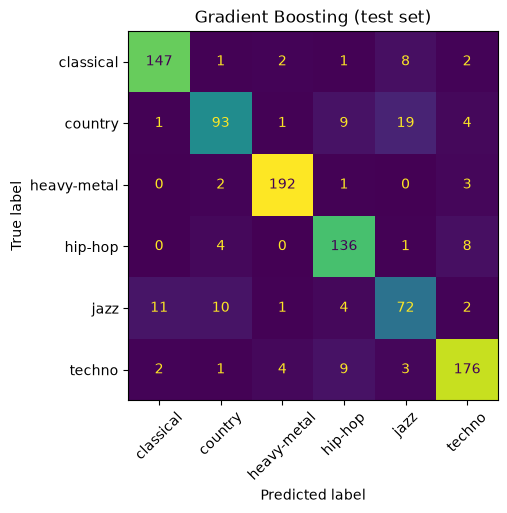

Correct: 816 of 930 songs (87.7%)
Correct per genre: classical 147/161, country 93/127, heavy-metal 192/198, hip-hop 136/149, jazz 72/100, techno 176/195
Biggest mistakes (true -> predicted): country -> jazz: 19, jazz -> classical: 11, jazz -> country: 10, techno -> hip-hop: 9, country -> hip-hop: 9


In [89]:
show_confusion('Gradient Boosting')

#### Gradient Boosting confusion matrix:

The confusion matrix shows that the model correctly predicted 816 of the 930 songs (87.7%), which is the most of all
the models. It is the best or close to the best on every genre. Techno improves the most: 176 of 195 are correct,
compared to 161 for the Random Forest. The mix-ups between techno, heavy-metal and hip-hop are much smaller now
(at most 9 songs).

What is left are mostly the calm and acoustic genres: 19 country songs were predicted as jazz, 11 jazz songs as
classical and 10 jazz songs as country. Jazz is still the hardest genre with 72 of 100 correct. These are the same
genres that overlapped in the EDA, since jazz, classical and country are all quite calm and acoustic.

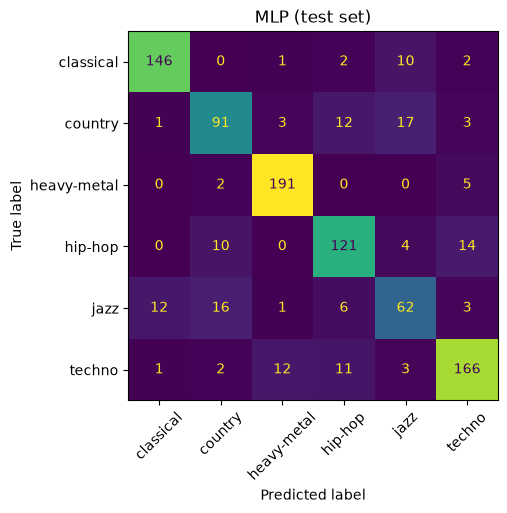

Correct: 777 of 930 songs (83.5%)
Correct per genre: classical 146/161, country 91/127, heavy-metal 191/198, hip-hop 121/149, jazz 62/100, techno 166/195
Biggest mistakes (true -> predicted): country -> jazz: 17, jazz -> country: 16, hip-hop -> techno: 14, techno -> heavy-metal: 12, jazz -> classical: 12


In [90]:
show_confusion('MLP')

#### MLP confusion matrix:

The confusion matrix shows that the model correctly predicted 777 of the 930 songs (83.5%), which is between the
baselines and the ensembles. It does well on classical (146 of 161) and techno (166 of 195), but hip-hop is weaker
than for the ensembles (121 of 149), and 14 hip-hop songs were predicted as techno.

Jazz and country are mixed up in both directions (17 country songs predicted as jazz, and 16 jazz songs as country),
and only 62 of 100 jazz songs are correct.

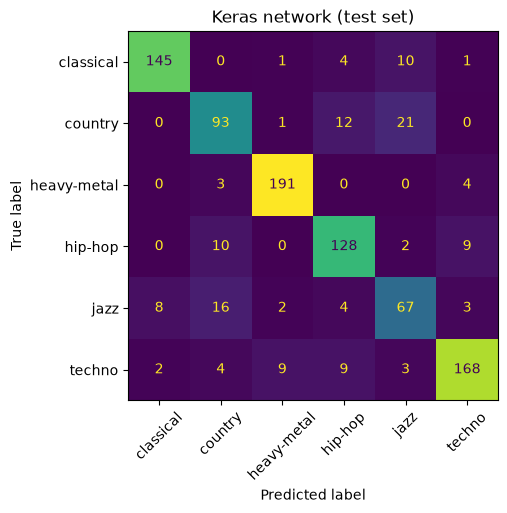

Correct: 792 of 930 songs (85.2%)
Correct per genre: classical 145/161, country 93/127, heavy-metal 191/198, hip-hop 128/149, jazz 67/100, techno 168/195
Biggest mistakes (true -> predicted): country -> jazz: 21, jazz -> country: 16, country -> hip-hop: 12, hip-hop -> country: 10, classical -> jazz: 10


In [91]:
show_confusion('Keras network')

#### Keras network confusion matrix:

The confusion matrix shows that the model correctly predicted 792 of the 930 songs (85.2%), which is better than
the MLP and almost as good as the Random Forest. Heavy-metal (191 of 198) and techno (168 of 195) do well.

The biggest problem is country and jazz again: 21 country songs were predicted as jazz and 16 jazz songs as country, so only 67 of 100 jazz songs are correct. Country and hip-hop are also mixed up in both directions (12 and 10 songs), and 10 classical songs were predicted as jazz.

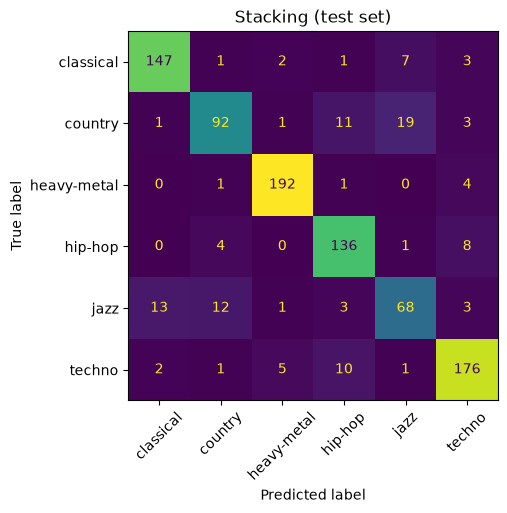

Correct: 811 of 930 songs (87.2%)
Correct per genre: classical 147/161, country 92/127, heavy-metal 192/198, hip-hop 136/149, jazz 68/100, techno 176/195
Biggest mistakes (true -> predicted): country -> jazz: 19, jazz -> classical: 13, jazz -> country: 12, country -> hip-hop: 11, techno -> hip-hop: 10


In [92]:
show_confusion('Stacking')

#### Stacking confusion matrix:

The confusion matrix shows that the model correctly predicted 811 of the 930 songs (87.2%), almost the same as
Gradient Boosting (816). The numbers for classical, heavy-metal, hip-hop and techno are almost identical to
Gradient Boosting. The only real difference is jazz, where stacking gets 68 of 100 right and Gradient Boosting 72.

The biggest mistakes are also the same: 19 country songs predicted as jazz, and jazz mixed up with classical (13)
and country (12). This supports what I saw in the cross-validation: combining the models doesn't fix the mistakes,
because all the base models struggle with the same songs.

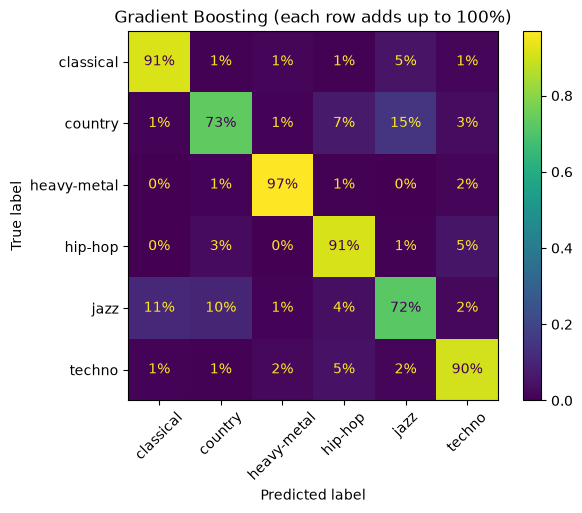

              precision    recall  f1-score   support

   classical       0.91      0.91      0.91       161
     country       0.84      0.73      0.78       127
 heavy-metal       0.96      0.97      0.96       198
     hip-hop       0.85      0.91      0.88       149
        jazz       0.70      0.72      0.71       100
      techno       0.90      0.90      0.90       195

    accuracy                           0.88       930
   macro avg       0.86      0.86      0.86       930
weighted avg       0.88      0.88      0.88       930



In [93]:
# The best model from cross-validation in more detail
best_pred = test_predictions[best_name]

ConfusionMatrixDisplay.from_predictions(test_targets, best_pred, display_labels=label_encoder.classes_,
                                        normalize='true', values_format='.0%', xticks_rotation=45)
plt.title(f'{best_name} (each row adds up to 100%)')
plt.show()

print(classification_report(test_targets, best_pred, target_names=label_encoder.classes_))

### Interpretation

I look at Gradient Boosting in more detail, since it is my final model.

The normalized confusion matrix shows which share of each genre ends up in each predicted genre. Heavy-metal is
almost perfect (97%), and classical, hip-hop and techno are all at 90 to 91%. Country (73%) and jazz (72%) are
clearly the hardest genres: 15% of the country songs are predicted as jazz, and the jazz mistakes are spread over
classical (11%) and country (10%).

The classification report shows the same thing. Heavy-metal has an F1 of 0.96, classical and techno 0.90 to 0.91 and
hip-hop 0.88, while country (0.78) and jazz (0.71) are much lower.

Precision and recall are not always equal. Country has a precision of 0.84 but a recall of only 0.73: when the model
says country it is usually right, but it misses many country songs, mostly to jazz. Hip-hop is the opposite, with a
recall of 0.91 and a precision of 0.85: almost all hip-hop songs are found, but some country and techno songs are
also called hip-hop.

The macro average (0.86) is lower than the weighted average (0.88). This is because the two hardest genres, jazz and
country, are also the two smallest genres after the cleaning. The weighted average gives them less weight, so it
hides part of the problem. This is why I use the macro average to compare the models.

The mistakes fit with the EDA: jazz, country and classical are all calm and acoustic, so they are close to each
other on the most important features.

## ROC and precision-recall curves

The scores above only look at the final prediction. The curves use the predicted *probabilities*
instead, and show how the model does for every possible threshold.

- **ROC curve:** the true positive rate (share of the songs of a genre that are found) against the
  false positive rate (share of the other songs that are wrongly called that genre). A perfect model
  goes straight to the top-left corner. The area under the curve (AUC) is 1.0 for a perfect model and
  0.5 for random guessing.
- **Precision-recall curve:** precision against recall. A perfect model stays at precision 1.0 for
  every recall. AP (average precision) summarizes the curve in one number.

With six genres, every genre is compared against all the other genres together ("one vs rest").

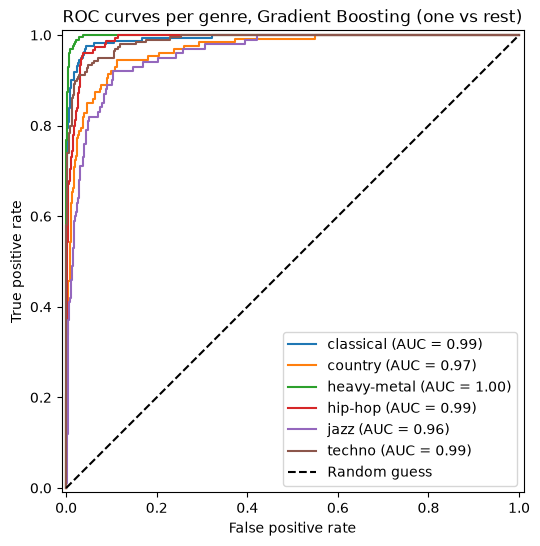

In [94]:
best_proba = test_probabilities[best_name]

fig, ax = plt.subplots(figsize=(7, 6))
for i, genre in enumerate(label_encoder.classes_):
    RocCurveDisplay.from_predictions(test_targets == i, best_proba[:, i], name=genre, ax=ax)

ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title(f'ROC curves per genre, {best_name} (one vs rest)')
ax.legend(loc='lower right')
plt.show()

### Interpretation

Every genre has an AUC between 0.96 and 1.00, so the model ranks the songs of every genre well. Heavy-metal is
almost perfect (1.00), and its curve goes straight up to the top-left corner. Classical, hip-hop and techno follow
with 0.99. Jazz (0.96) and country (0.97) are the lowest, and their curves rise more slowly, which matches the
confusion matrix, where these two genres had the most mistakes.

The ROC curve looks very good even for jazz. The reason is that there are many more "not jazz" songs (830) than jazz
songs (100) in the test set, so even quite a few wrong jazz predictions only give a small false positive rate. The
precision-recall curves below show the problem more clearly.

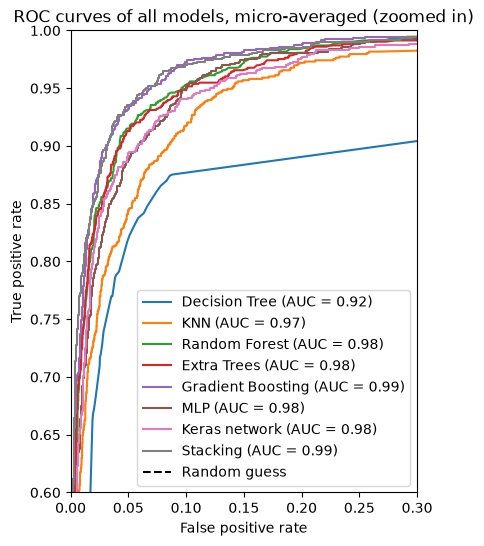

In [95]:
# Micro average: all six one-vs-rest problems are put together into one big yes/no problem,
# so every model gets one curve
test_binary = label_binarize(test_targets, classes=range(6))      # one yes/no column per genre

fig, ax = plt.subplots(figsize=(7, 6))
for name in best_models:
    RocCurveDisplay.from_predictions(test_binary.ravel(), test_probabilities[name].ravel(), name=name, ax=ax)

ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_xlim(0, 0.3)       # zoomed in on the top-left corner, otherwise the curves overlap
ax.set_ylim(0.6, 1.0)
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC curves of all models, micro-averaged (zoomed in)')
ax.legend(loc='lower right')
plt.show()

### Interpretation

This plot shows one micro-averaged ROC curve per model, zoomed in on the top-left corner. Gradient Boosting and
Stacking have the best curves (AUC 0.99): they reach a true positive rate of about 0.9 at a false positive rate of
only about 0.05. The other ensembles and the neural networks are close behind (0.98), and KNN is a bit lower (0.97).

The Decision Tree stands out with an AUC of 0.92 and a curve with a sharp corner. A single tree gives the same
probability to all the songs in the same leaf, so it only has a few different probability values, and the curve
jumps instead of being smooth. The other models give more fine-grained probabilities, so they can rank the songs better.

The AUC values in the plot are a bit higher than in the test table, because the table uses the macro average (one
AUC per genre, then the average), while this plot uses the micro average. The order of the models is the same as in
the test table, so the probabilities tell the same story as the predictions.

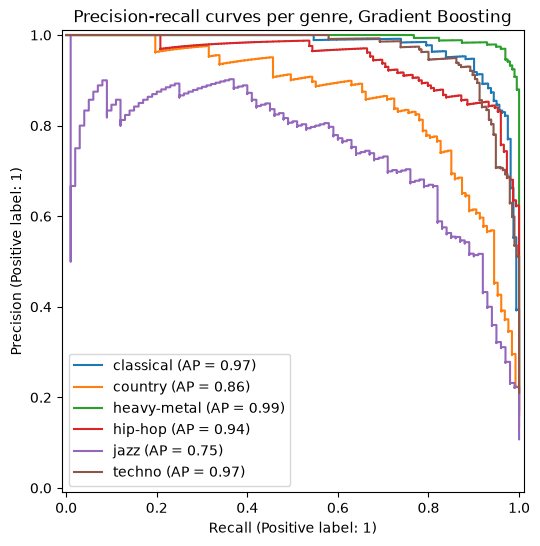

In [96]:
fig, ax = plt.subplots(figsize=(7, 6))
for i, genre in enumerate(label_encoder.classes_):
    PrecisionRecallDisplay.from_predictions(test_targets == i, best_proba[:, i], name=genre, ax=ax)

ax.set_title(f'Precision-recall curves per genre, {best_name}')
ax.legend(loc='lower left')
plt.show()

### Interpretation

The precision-recall curves show a much bigger difference between the genres than the ROC curves. Heavy-metal
(AP 0.99), classical (0.97) and techno (0.97) keep a precision close to 1.0 until a recall of about 0.8, so the model
can find most of these songs without many wrong ones. Hip-hop is a bit lower (0.94).

Country (0.86) and especially jazz (0.75) are clearly worse. For jazz, the precision is only about 0.8 at a recall of
0.4, and it falls steadily after that: to find more of the jazz songs, the model has to accept more and more songs
from other genres. This is because jazz is the smallest genre, and it overlaps with both classical and country.

This is a good example of why ROC alone can look too positive when the classes are imbalanced: jazz has a ROC-AUC of
0.96, but an average precision of only 0.75.

# FURTHER ANALYSIS

## Audio only: how much does popularity add?

In the EDA I argued that `popularity` says something about listeners, not about how a song sounds,
and every tuning chose to keep it. Here I measure how much of each model's score comes from
`popularity`: I take every tuned model, keep all its settings but drop `popularity`, and calculate the
cross-validation and test scores again.

In [97]:
def without_popularity(model):
    """A fresh, unfitted copy of a tuned model with the same settings, but with popularity dropped."""
    model = clone(model)
    if isinstance(model, StackingClassifier):
        # In the stacking model, popularity is inside the preprocessing of every base model
        model.set_params(**{f'{name}__preprocess__popularity': 'drop' for name, _ in model.estimators})
    else:
        model.set_params(preprocess__popularity='drop')
    return model


audio_rows = {}
for name, model in best_models.items():
    audio_model = without_popularity(model)
    n_jobs = 1 if name == 'Keras network' else -1      # Keras is trained one fold at a time, like in its search
    scores = cross_val_score(audio_model, train_features, train_targets, cv=cv, scoring='f1_macro', n_jobs=n_jobs)
    audio_model.fit(train_features, train_targets)
    audio_rows[name] = {
        'CV F1 with popularity': cv_table.loc[name, 'CV F1'],
        'CV F1 audio only': scores.mean(),
        'Test F1 with popularity': test_results_df.loc[name, 'F1'],
        'Test F1 audio only': f1_score(test_targets, audio_model.predict(test_features), average='macro'),
    }

audio_table = pd.DataFrame(audio_rows).T
audio_table['Test F1 lost'] = audio_table['Test F1 with popularity'] - audio_table['Test F1 audio only']
audio_table = audio_table.sort_values('Test F1 audio only', ascending=False).round(3)
audio_table

,CV F1 with popularity,CV F1 audio only,Test F1 with popularity,Test F1 audio only,Test F1 lost
Stacking,0.869,0.797,0.852,0.793,0.059
Random Forest,0.850,0.793,0.836,0.790,0.046
Gradient Boosting,0.868,0.788,0.859,0.777,0.082
Keras network,0.800,0.758,0.831,0.769,0.062
Extra Trees,0.851,0.778,0.838,0.769,0.069
MLP,0.814,0.754,0.813,0.752,0.061
KNN,0.793,0.745,0.784,0.747,0.037
Decision Tree,0.779,0.690,0.773,0.676,0.097


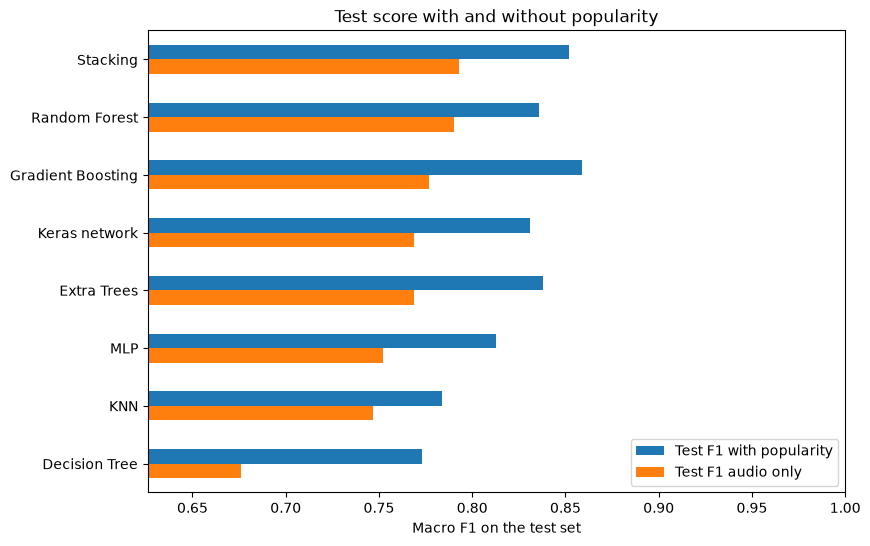

In [98]:
audio_table[['Test F1 with popularity', 'Test F1 audio only']].plot(kind='barh', figsize=(9, 6))
plt.gca().invert_yaxis()
plt.xlim(audio_table['Test F1 audio only'].min() - 0.05, 1.0)
plt.xlabel('Macro F1 on the test set')
plt.title('Test score with and without popularity')
plt.legend(loc='lower right')
plt.show()

### Interpretation

Every model gets worse without `popularity`. On the test set, the macro F1 drops by between 0.037 (KNN) and 0.097
(Decision Tree). For my final model, Gradient Boosting, it drops from 0.859 to 0.777.

Interestingly, the order of the models changes. With `popularity`, Gradient Boosting is the best model. With only
the audio features, Stacking (0.793) and the Random Forest (0.790) are the best, and Gradient Boosting drops to third
(0.777). One reason could be that all the settings were tuned with `popularity`, and Gradient Boosting might rely on
it more than the others. A model tuned without `popularity` from the start might do a bit better.

This confirms what I suspected in the EDA. `popularity` helps mostly because jazz, country and classical have many
songs with popularity 0, which is a pattern in how people listen, not in how the music sounds.

What I take from this: if the goal is just the highest score on this dataset, `popularity` should be kept. But if
the goal is to recognise a genre from the sound, which was the goal I set at the start, the honest answer is the
audio-only score: about 0.79 for the best models. That is still far above random guessing (0.16).

## Which features matter? Permutation importance

Permutation importance measures how much the score drops when the values of one feature are shuffled
randomly, so the feature becomes useless while everything else stays the same. A big drop means the
model depends a lot on that feature. It works for any model, and it measures the original columns,
so `key` counts as one feature even when it is one-hot encoded. I calculate it on the test set for the
best model, and repeat the shuffling 10 times per feature.

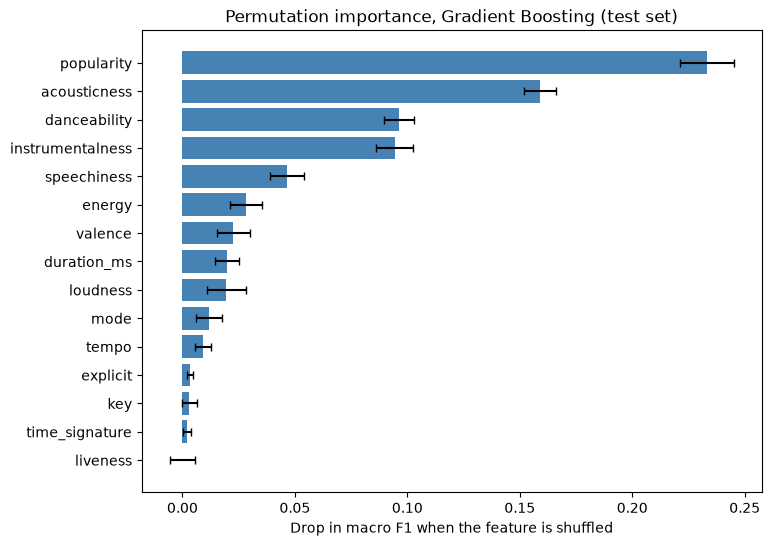

,importance,std
popularity,0.233,0.012
acousticness,0.159,0.007
danceability,0.096,0.007
instrumentalness,0.094,0.008
speechiness,0.046,0.007
energy,0.028,0.007
valence,0.023,0.007
duration_ms,0.020,0.005
loudness,0.020,0.009
mode,0.012,0.006


In [99]:
best_model = best_models[best_name]
importance = permutation_importance(best_model, test_features, test_targets, scoring='f1_macro',
                                    n_repeats=10, random_state=random_state, n_jobs=-1)

importance_df = pd.DataFrame({'importance': importance.importances_mean, 'std': importance.importances_std},
                             index=test_features.columns).sort_values('importance')

plt.figure(figsize=(8, 6))
plt.barh(importance_df.index, importance_df['importance'], xerr=importance_df['std'], color='steelblue', capsize=3)
plt.xlabel('Drop in macro F1 when the feature is shuffled')
plt.title(f'Permutation importance, {best_name} (test set)')
plt.show()

importance_df.sort_values('importance', ascending=False).round(3)

### Interpretation

`popularity` is the most important feature for Gradient Boosting: shuffling it lowers the macro F1 by 0.233. That
fits with the audio-only comparison above, where the test F1 dropped from 0.859 to 0.777 without it. The two numbers
are not the same: when the model is trained without `popularity`, it can learn to use the other features instead,
but when `popularity` is only shuffled, the trained model still relies on it and gets confused.

The most important audio features are `acousticness` (0.159), `danceability` (0.096) and `instrumentalness` (0.094),
followed by `speechiness` (0.046). This matches my EDA very well. In the box plots, acousticness and instrumentalness
separated the calm genres (classical and jazz) from the rest, danceability separated hip-hop and techno from the
others, and speechiness mostly helped to recognise hip-hop.

Some features that looked useful in the EDA are less important here. `energy` (0.028) and `loudness` (0.020)
separated the genres well in the box plots, but they are strongly correlated with each other and with acousticness
(0.76 and -0.73). When one of them is shuffled, the model can still get almost the same information from the others,
so each of them looks less important on its own.

`key`, `time_signature`, `explicit` and `liveness` are almost useless (0.003 or less). This also fits with the EDA,
where key and time signature only showed small differences between the genres, and liveness looked the same for
every genre.

## Error analysis: which songs does the model get wrong?

The confusion matrix shows how many songs are mixed up. Here I look at the actual songs behind the
most common mistakes, using the song names I saved before dropping them.

In [100]:
genre_names = label_encoder.classes_
mistakes = pd.DataFrame({'true genre': genre_names[test_targets.to_numpy()],
                         'predicted genre': genre_names[best_pred]}, index=test_targets.index)
mistakes = mistakes[mistakes['true genre'] != mistakes['predicted genre']]

print(f"{best_name} got {len(mistakes)} of {len(test_targets)} test songs wrong.\n")
print("Most common mistakes:")
print(mistakes.value_counts().head(8).to_string())

Gradient Boosting got 114 of 930 test songs wrong.

Most common mistakes:
true genre  predicted genre
country     jazz               19
jazz        classical          11
            country            10
country     hip-hop             9
techno      hip-hop             9
classical   jazz                8
hip-hop     techno              8
country     techno              4


In [101]:
# Some of the songs behind the three most common mistakes, with a few of their features
examples = mistakes.join(song_info).join(
    test_features[['acousticness', 'energy', 'instrumentalness', 'speechiness', 'popularity']])

for true_genre, predicted_genre in mistakes.value_counts().head(3).index:
    print(f"\n{true_genre} predicted as {predicted_genre}:")
    rows = examples[(examples['true genre'] == true_genre) & (examples['predicted genre'] == predicted_genre)]
    display(rows.drop(columns=['true genre', 'predicted genre']).head(5))


country predicted as jazz:


,track_name,artists,album_name,acousticness,energy,instrumentalness,speechiness,popularity
19003,Something in the Orange,Zach Bryan,New Country,0.555,0.192,0.000008,0.0400,3
19032,"Burn, Burn, Burn",Zach Bryan,Burn Burn Burn - Hot Country Hits,0.897,0.296,0.000050,0.0755,0
19093,Silent Night,Cody Johnson;Clara Johnson;Brandi Johnson;Cori...,Happy Country Christmas,0.687,0.131,0.000000,0.0280,0
19145,O Christmas Tree,George Strait,Weihnachten Playlist,0.794,0.295,0.000000,0.0287,0
19188,Better Boat,Kenny Chesney;Mindy Smith,Finest Country,0.827,0.265,0.000023,0.0302,0



jazz predicted as classical:


,track_name,artists,album_name,acousticness,energy,instrumentalness,speechiness,popularity
64564,Love Will Follow,George Howard,Cool Covers - Smooth Jazz Plays The Hits!,0.580,0.6000,0.452,0.0324,45
64654,Day Dream,Bill Charlap Trio,Street Of Dreams,0.909,0.0951,0.890,0.0388,65
64707,"Goodbye, Old Girl",Art Farmer,Art,0.994,0.0288,0.895,0.0467,51
64723,Delarna,Tommy Flanagan,The Smart Attitude of Tommy Flanagan,0.698,0.2420,0.460,0.0344,40
64813,Strange (feat. Hillary Smith),Kris Bowers;Hillary Smith,Bridgerton (Covers from the Netflix Original S...,0.989,0.1500,0.972,0.0342,59



jazz predicted as country:


,track_name,artists,album_name,acousticness,energy,instrumentalness,speechiness,popularity
64032,Christmas Don't Be Late,Norah Jones,Holidays Are Coming,0.7510,0.374,0.000058,0.0280,0
64100,Nothing's Gonna Change My Love for You,George Benson,20/20,0.7640,0.614,0.000000,0.0306,71
64451,Sway - Sped Up Version,Michael Bublé,Sway (Sped Up Version),0.7300,0.671,0.000002,0.0422,66
64517,Winter Wonderland,Tony Bennett;Lady Gaga,Rock Christmas 2022 - The Very Best Of,0.7270,0.497,0.000039,0.0319,0
64538,Go Tell It On The Mountain / Ain't No Mountain...,Gregory Porter;Anita Wilson,Soulful Christmas,0.0507,0.790,0.000000,0.0535,0


### Interpretation

Gradient Boosting got 114 of the 930 test songs wrong. The most common mistakes are country predicted as jazz (19),
jazz predicted as classical (11) and jazz predicted as country (10).

Looking at the actual songs makes the mistakes easier to understand:

- **Country predicted as jazz:** these are calm, acoustic country songs, like *Something in the Orange* by Zach
  Bryan, and Christmas songs like *Silent Night* and *O Christmas Tree*. They have a high acousticness (0.56 to 0.90),
  a low energy (0.13 to 0.30) and a popularity of 0 or close to it, which is exactly the typical profile of a jazz
  song in this dataset.
- **Jazz predicted as classical:** these are instrumental jazz pieces, like *Day Dream* by Bill Charlap Trio and
  *Goodbye, Old Girl* by Art Farmer. They have a very high acousticness and instrumentalness (up to 0.99 and 0.97)
  and a low energy. Without vocals and with acoustic instruments, they look like classical music to the model.
- **Jazz predicted as country:** these are vocal jazz songs, and many of them are Christmas songs, like *Winter
  Wonderland* by Tony Bennett and Lady Gaga, and *Christmas Don't Be Late* by Norah Jones. They have vocals (low
  instrumentalness), medium energy and quite high acousticness, which is the typical profile of a country song.

So many of the mistakes are understandable. Christmas songs especially seem to be hard, since they appear in several
genres and are often recorded in a calm, acoustic style no matter what the genre is. Some of these songs could also
be argued to belong to both genres, since the genre label comes from the playlist the song was found in, and not
from the song itself.

## Learning curve: would more data help?

A learning curve trains the best model on bigger and bigger parts of the training data and shows the
training score and the cross-validation score. If the cross-validation score is still rising at the
end, more data would probably help. If it has flattened out, more data of the same kind would not help much.

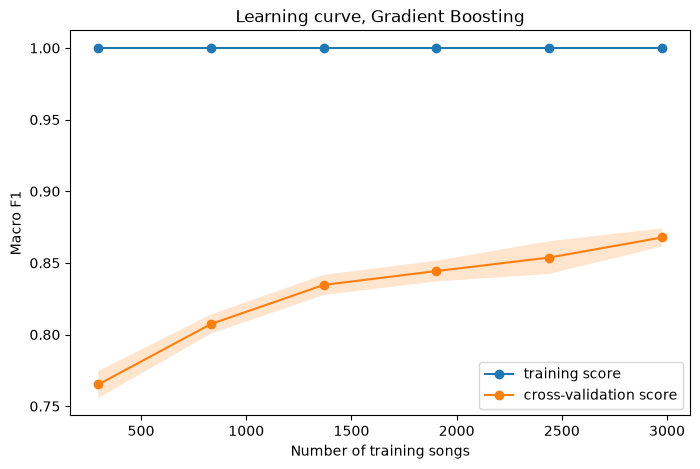

 songs  train F1  CV F1
   297       1.0  0.765
   833       1.0  0.807
  1368       1.0  0.835
  1904       1.0  0.844
  2440       1.0  0.854
  2976       1.0  0.868


In [102]:
sizes, train_scores, val_scores = learning_curve(clone(best_model), train_features, train_targets, cv=cv,
                                                 scoring='f1_macro', train_sizes=np.linspace(0.1, 1.0, 6),
                                                 n_jobs=-1)

plt.figure(figsize=(8, 5))
for scores, label in [(train_scores, 'training score'), (val_scores, 'cross-validation score')]:
    plt.plot(sizes, scores.mean(axis=1), 'o-', label=label)
    plt.fill_between(sizes, scores.mean(axis=1) - scores.std(axis=1),
                     scores.mean(axis=1) + scores.std(axis=1), alpha=0.2)
plt.xlabel('Number of training songs')
plt.ylabel('Macro F1')
plt.title(f'Learning curve, {best_name}')
plt.legend()
plt.show()

print(pd.DataFrame({'songs': sizes, 'train F1': train_scores.mean(axis=1),
                    'CV F1': val_scores.mean(axis=1)}).round(3).to_string(index=False))

### Interpretation

The training score is 1.0 for every size, so Gradient Boosting always fits its training data perfectly. The
cross-validation score rises the whole time: from 0.765 with about 300 songs to 0.868 with about 3,000 songs. It
rises fastest in the beginning, but it is still rising at the end (from 0.854 to 0.868 in the last step).

This means that more data would probably help. The big gap between the training score and the cross-validation
score (about 0.13) points in the same direction: the model could learn more if it had more examples. This is a cost
of removing the re-released copies, which made the dataset smaller, especially for jazz and country. A natural next
step would be to collect more songs for these genres.

# CONCLUSION

### What I did

I used the Spotify Tracks dataset from Kaggle to predict the genre of a song from its audio features. The full
dataset has 114 genres, but many of them share the same songs, so I chose six genres that share almost no songs:
classical, country, heavy-metal, hip-hop, jazz and techno.

### What I found in the data

- The most useful audio features for telling the genres apart are `acousticness`, `instrumentalness`,
  `danceability`, `energy` and `loudness`. No single feature separates all six genres.
- `popularity` differs a lot between the genres, but it describes listeners, not sound.
- The biggest data problem was hidden: the same recording is often released on several albums with a different
  `track_id`. 1,248 rows were such copies. If I had kept them, 25.8% of the test songs would have had an identical
  copy in the training data, and the model would have scored 1.000 on those songs but only 0.884 on truly new songs.
  After removing them, 4,650 songs were left, and the genres were no longer balanced (500 jazz songs vs 991
  heavy-metal songs).

### Processing and tuning

All the processing is inside a `Pipeline` with a `ColumnTransformer`, so the scaling and encoding are learned only
from the training folds. The processing alternatives were tuned together with the model parameters, using the same
5 folds for every model and the macro F1 score:

- Keeping `popularity` was always better.
- Scaling and the power transform were very important for KNN (about 0.54 vs 0.74 on average), but don't matter for trees.
- One-hot encoding or keeping `key` and `time_signature` as numbers made almost no difference.
- `class_weight='balanced'` helped the Random Forest a little, but not the other trees.

### Results

| Model | CV macro F1 | Test macro F1 | Test accuracy |
|---|---|---|---|
| Random guess | 0.162 | 0.158 | 0.159 |
| Decision Tree (baseline) | 0.779 | 0.773 | 0.792 |
| KNN (baseline) | 0.793 | 0.784 | 0.810 |
| Random Forest | 0.850 | 0.836 | 0.856 |
| Extra Trees | 0.851 | 0.838 | 0.858 |
| **Gradient Boosting (final model)** | **0.868** | **0.859** | **0.877** |
| MLP | 0.814 | 0.813 | 0.835 |
| Keras network | 0.800 | 0.831 | 0.852 |
| Stacking (extra) | 0.869 | 0.852 | 0.872 |

The tree ensembles were the best models, the neural networks came in the middle, and the baselines were the weakest.
I chose **Gradient Boosting** as my final model before looking at the test set: it was within one standard deviation
of the stacking model in cross-validation, but simpler and five times faster. On the test set it was the best model,
with an accuracy of 0.877 and a macro F1 of 0.859. Combining the best models in a stacking ensemble didn't help,
because all the models struggle with the same songs.

The hardest genres are jazz (F1 0.71) and country (0.78). They are mostly mixed up with each other and with
classical, which fits with the EDA, since these three genres are all calm and acoustic. Looking at the actual songs,
many of the mistakes are understandable: calm acoustic country songs, instrumental jazz pieces and Christmas songs.

### How much of this is about the sound?

Without `popularity`, the test F1 of the best models drops to about 0.79, and to 0.777 for Gradient Boosting. So
around 0.05 to 0.08 of the score comes from a pattern in how people listen, not in how the music sounds. If the
question is "can a model recognise a genre from the sound?", the honest answer is the audio-only score: about 0.79,
which is still far above random guessing (0.16).

### Limitations

- The genre labels come from the playlists the songs were found in, not from the songs themselves. Some songs
  (for example Christmas songs) could fit in more than one genre, so some of the "mistakes" may not be real mistakes.
- I only used six quite different genres. With similar genres, or all 114, the task would be much harder.
- After removing the copies, the dataset is smaller and imbalanced, and the learning curve shows that more data
  would help.
- All the settings were tuned with `popularity` kept. Models tuned without it from the start might do a bit better
  on audio only.
- I found the copies by looking for exactly the same audio values. Different versions of the same song, like a
  remaster, have slightly different values and could still be in the data.

### What I would do next

- Collect more songs for jazz and country, since the learning curve is still rising.
- Tune the models again without `popularity`, to get the best possible audio-only model.
- Try XGBoost or LightGBM, which are similar to Gradient Boosting but have more options.
- Add more genres, including some that sound similar, to see where the models start to fail.